# Loan Approval Prediction: Feature Engineering and Data Preprocessing for Machine Learning
**AnalystLab Africa Data Science Internship | Week 2 | Dataset: Loan Prediction Problem (Option 2)**

| | |
|---|---|
| **Analyst** | Cheruiyot Nickson Kirui |
| **Business problem** | Help a home-loan lender decide quickly and consistently whether an application should be approved |
| **Target variable** | `Loan_Status` (Y = approved, N = rejected), encoded as `loan_approved` (1 / 0) |
| **Goal this week** | Turn the raw application data into a clean, documented, machine-learning-ready dataset |

### Notebook map
1. **Part 1** Business understanding (summary; the full report is in `reports/`)
2. **Part 2** Data inspection
3. **Part 3** Data cleaning, feature engineering, encoding, outlier handling and scaling
4. **Part 4** Feature selection
5. **Part 5** Final machine-learning dataset, readiness check and answers to the seven business questions

### The one rule that shapes the whole pipeline: no data leakage
Anything the pipeline *learns from data* (the most common category, the median, outlier limits, the mean used for scaling) is learned **from the training rows only**. The data is split into **train (80%)** and **hold-out (20%)** *before* any of these values are calculated. The hold-out rows are then transformed using the training values. This keeps the hold-out set a fair test of how a model will behave on new applicants.

## Part 1: Business Understanding (summary)
* **Business problem:** *Dream Housing Finance* offers home loans across urban, semi-urban and rural areas. Customers apply, and the company then checks eligibility using details such as gender, marital status, education, dependents, income, loan amount and credit history. Manual checking is slow and can be inconsistent.
* **Objective:** prepare the application data so that a machine learning model can later predict whether an application should be approved.
* **Target variable:** `Loan_Status` (Y/N).
* **Why predictive modelling matters:** faster decisions, consistent criteria, lower processing cost and better risk control.
* **Expected impact:** shorter approval times, fewer risky approvals and more time for staff to review borderline cases.

The full 1 to 2 page **Business Understanding Report** is in `reports/Business_Understanding_Report.pdf`.

## Setup
Libraries, folders, a fixed random seed (so results can be reproduced) and two small helpers.

In [1]:
import json, platform, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from scipy import stats

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import mutual_info_classif
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, ConfusionMatrixDisplay)
import sklearn

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
sns.set_theme(style="whitegrid", context="notebook")

RANDOM_STATE = 42
RAW_DIR, PROC_DIR, IMG_DIR = Path("data/raw"), Path("data/processed"), Path("images")
for folder in (PROC_DIR, IMG_DIR):
    folder.mkdir(parents=True, exist_ok=True)

BLUE, GOLD, GREEN, RED, GREY = "#1F3A5F", "#D4A017", "#2E7D6B", "#B03A2E", "#6B7280"
STATUS_PALETTE = {"Y": GREEN, "N": RED}

def save_fig(name):
    # Tidy the layout, save the chart to images/ and show it.
    plt.tight_layout()
    plt.savefig(IMG_DIR / f"{name}.png", dpi=140, bbox_inches="tight")
    plt.show()

print(f"Python {platform.python_version()} | pandas {pd.__version__} | numpy {np.__version__} | scikit-learn {sklearn.__version__}")

Python 3.12.3 | pandas 3.0.2 | numpy 2.4.4 | scikit-learn 1.8.0


## Part 2: Data Inspection
The Kaggle download has two files. **`train`** has 614 applications **with** the outcome (`Loan_Status`), so it is the dataset used for preparation and modelling. **`test`** has 367 applications **without** the outcome, so it cannot be used to measure accuracy. It is used at the end only to prove the pipeline works on brand-new data.

### 2.1 Load the data and view the first 10 rows

In [2]:
raw      = pd.read_csv(RAW_DIR / "loan_train_original.csv")
raw_test = pd.read_csv(RAW_DIR / "loan_test_original.csv")
display(raw.head(10))

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.000,NaN,360.000,1.000,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,"1,508.000",128.000,360.000,1.000,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.000,66.000,360.000,1.000,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,"2,358.000",120.000,360.000,1.000,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.000,141.000,360.000,1.000,Urban,Y
5,LP001011,Male,Yes,2,Graduate,Yes,5417,"4,196.000",267.000,360.000,1.000,Urban,Y
6,LP001013,Male,Yes,0,Not Graduate,No,2333,"1,516.000",95.000,360.000,1.000,Urban,Y
7,LP001014,Male,Yes,3+,Graduate,No,3036,"2,504.000",158.000,360.000,0.000,Semiurban,N
8,LP001018,Male,Yes,2,Graduate,No,4006,"1,526.000",168.000,360.000,1.000,Urban,Y
9,LP001020,Male,Yes,1,Graduate,No,12841,"10,968.000",349.000,360.000,1.000,Semiurban,N


### 2.2 Structure: rows, columns and data types

In [3]:
print(f"Training file:  {raw.shape[0]} rows x {raw.shape[1]} columns")
print(f"Unlabelled test file: {raw_test.shape[0]} rows x {raw_test.shape[1]} columns (no Loan_Status)\n")
raw.info()
dtype_notes = pd.DataFrame({"dtype": raw.dtypes.astype(str), "unique_values": raw.nunique(), "example": raw.iloc[0]})
display(dtype_notes)

Training file:  614 rows x 13 columns
Unlabelled test file: 367 rows x 12 columns (no Loan_Status)

<class 'pandas.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            614 non-null    str    
 1   Gender             601 non-null    str    
 2   Married            611 non-null    str    
 3   Dependents         599 non-null    str    
 4   Education          614 non-null    str    
 5   Self_Employed      582 non-null    str    
 6   ApplicantIncome    614 non-null    int64  
 7   CoapplicantIncome  614 non-null    float64
 8   LoanAmount         592 non-null    float64
 9   Loan_Amount_Term   600 non-null    float64
 10  Credit_History     564 non-null    float64
 11  Property_Area      614 non-null    str    
 12  Loan_Status        614 non-null    str    
dtypes: float64(4), int64(1), str(8)
memory usage: 62.5 KB


,dtype,unique_values,example
Loan_ID,str,614,LP001002
Gender,str,2,Male
Married,str,2,No
Dependents,str,4,0
Education,str,2,Graduate
Self_Employed,str,2,No
ApplicantIncome,int64,505,5849
CoapplicantIncome,float64,287,0.000
LoanAmount,float64,203,NaN
Loan_Amount_Term,float64,10,360.000


### 2.3 Missing values

,missing,percent
Credit_History,50,8.143
Self_Employed,32,5.212
LoanAmount,22,3.583
Dependents,15,2.443
Loan_Amount_Term,14,2.280
Gender,13,2.117
Married,3,0.489


Rows with at least one missing value: 134 of 614 (21.8%)


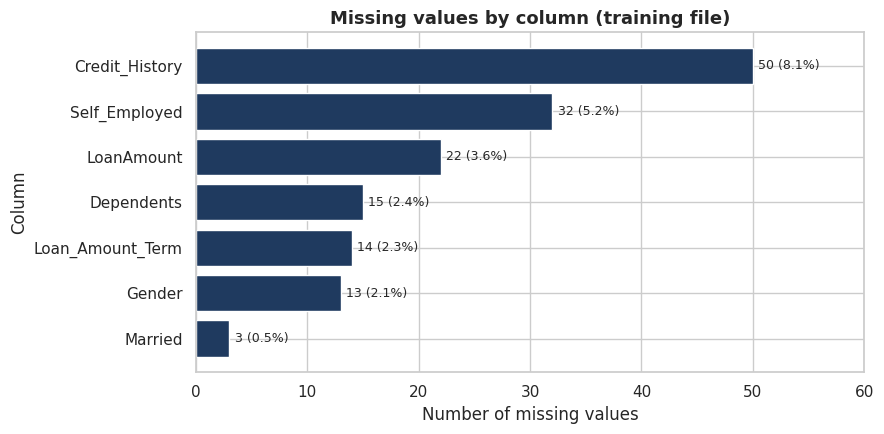

In [4]:
miss = raw.isna().sum().to_frame("missing")
miss["percent"] = 100 * miss["missing"] / len(raw)
miss = miss[miss["missing"] > 0].sort_values("missing", ascending=False)
display(miss)
print(f"Rows with at least one missing value: {raw.isna().any(axis=1).sum()} of {len(raw)} ({raw.isna().any(axis=1).mean():.1%})")

fig, ax = plt.subplots(figsize=(9, 4.5))
bars = ax.barh(miss.index[::-1], miss["missing"][::-1], color=BLUE)
for b, p in zip(bars, miss["percent"][::-1]):
    ax.text(b.get_width() + 0.5, b.get_y() + b.get_height() / 2, f"{int(b.get_width())} ({p:.1f}%)", va="center", fontsize=9)
ax.set_xlim(0, miss["missing"].max() * 1.2)
ax.set_title("Missing values by column (training file)", fontsize=13, fontweight="bold")
ax.set_xlabel("Number of missing values"); ax.set_ylabel("Column")
save_fig("01_missing_values")

### 2.4 Duplicate records

In [5]:
print("Fully duplicated rows:                          ", raw.duplicated().sum())
print("Duplicated rows ignoring the Loan_ID column:    ", raw.drop(columns="Loan_ID").duplicated().sum())
print("Is Loan_ID unique?                              ", raw["Loan_ID"].is_unique)

Fully duplicated rows:                           0
Duplicated rows ignoring the Loan_ID column:     0
Is Loan_ID unique?                               True


### 2.5 Summary statistics

In [6]:
print("Numeric columns:")
display(raw.describe().T.assign(skewness=raw.select_dtypes("number").skew()))
print("Categorical columns:")
display(raw.describe(include=["object", "string"]).T)
print("Value counts of the discrete columns:")
for c in ["Gender", "Married", "Dependents", "Education", "Self_Employed", "Property_Area", "Credit_History", "Loan_Amount_Term"]:
    print(f"  {c:<17}", raw[c].value_counts(dropna=False).to_dict())

Numeric columns:


,count,mean,std,min,25%,50%,75%,max,skewness
ApplicantIncome,614.000,"5,403.459","6,109.042",150.000,"2,877.500","3,812.500","5,795.000","81,000.000",6.540
CoapplicantIncome,614.000,"1,621.246","2,926.248",0.000,0.000,"1,188.500","2,297.250","41,667.000",7.492
LoanAmount,592.000,146.412,85.587,9.000,100.000,128.000,168.000,700.000,2.678
Loan_Amount_Term,600.000,342.000,65.120,12.000,360.000,360.000,360.000,480.000,-2.362
Credit_History,564.000,0.842,0.365,0.000,1.000,1.000,1.000,1.000,-1.882


Categorical columns:


,count,unique,top,freq
Loan_ID,614,614,LP001002,1
Gender,601,2,Male,489
Married,611,2,Yes,398
Dependents,599,4,0,345
Education,614,2,Graduate,480
Self_Employed,582,2,No,500
Property_Area,614,3,Semiurban,233
Loan_Status,614,2,Y,422


Value counts of the discrete columns:
  Gender            {'Male': 489, 'Female': 112, nan: 13}
  Married           {'Yes': 398, 'No': 213, nan: 3}
  Dependents        {'0': 345, '1': 102, '2': 101, '3+': 51, nan: 15}
  Education         {'Graduate': 480, 'Not Graduate': 134}
  Self_Employed     {'No': 500, 'Yes': 82, nan: 32}
  Property_Area     {'Semiurban': 233, 'Urban': 202, 'Rural': 179}
  Credit_History    {1.0: 475, 0.0: 89, nan: 50}
  Loan_Amount_Term  {360.0: 512, 180.0: 44, 480.0: 15, nan: 14, 300.0: 13, 240.0: 4, 84.0: 4, 120.0: 3, 60.0: 2, 36.0: 2, 12.0: 1}


### 2.6 The target variable and first patterns

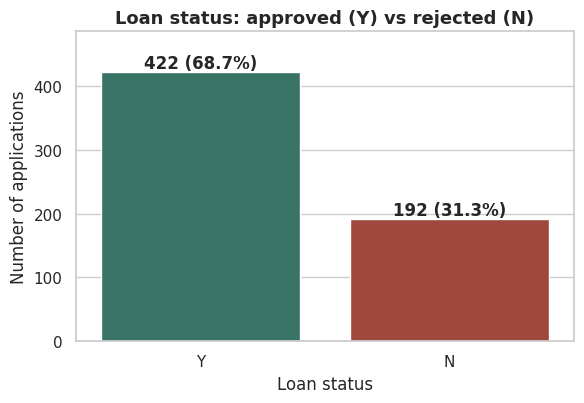

Approval rate: 68.7%. A model that always says 'approve' would already be 68.7% accurate.


In [7]:
counts = raw["Loan_Status"].value_counts()
fig, ax = plt.subplots(figsize=(6, 4.2))
sns.countplot(data=raw, x="Loan_Status", order=["Y", "N"], hue="Loan_Status", palette=STATUS_PALETTE, legend=False, ax=ax)
for i, lab in enumerate(["Y", "N"]):
    ax.text(i, counts[lab], f"{counts[lab]} ({counts[lab] / len(raw):.1%})", ha="center", va="bottom", fontweight="bold")
ax.set_ylim(0, counts.max() * 1.15)
ax.set_title("Loan status: approved (Y) vs rejected (N)", fontsize=13, fontweight="bold")
ax.set_xlabel("Loan status"); ax.set_ylabel("Number of applications")
save_fig("02_target_distribution")
print(f"Approval rate: {counts['Y'] / len(raw):.1%}. A model that always says 'approve' would already be {counts['Y'] / len(raw):.1%} accurate.")

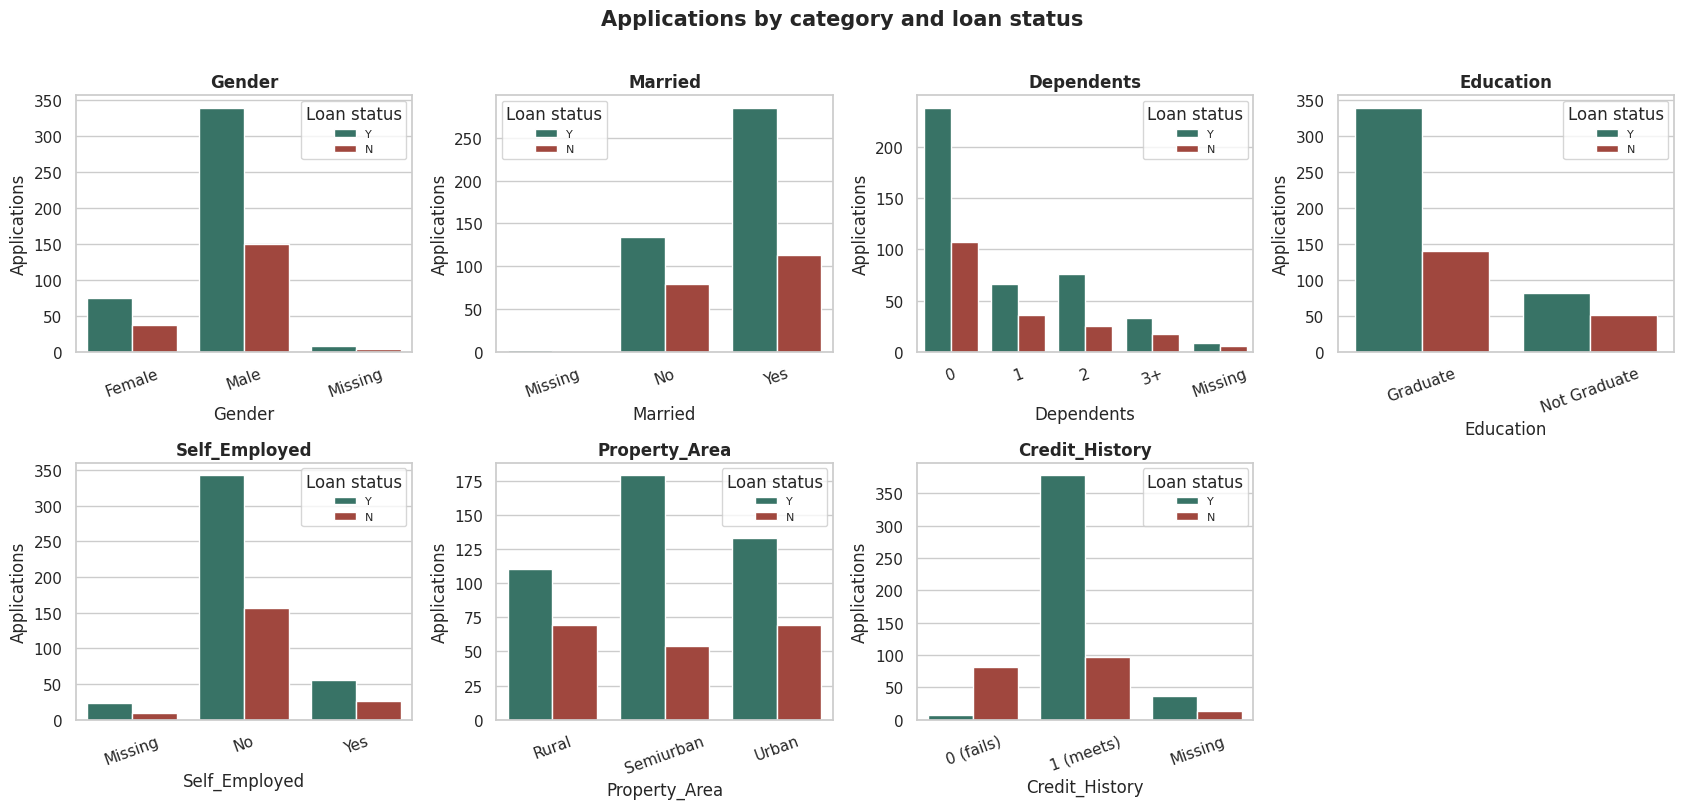

Approval rate by Credit_History (note the missing group):


Loan_Status,N,Y,applications
Credit_History,,,
0,92.100,7.900,89
1,20.400,79.600,475
Missing,26.000,74.000,50


In [8]:
# Approval patterns by category (missing values shown as their own bar so nothing is hidden)
def as_label(s):
    return s.map(lambda v: "Missing" if pd.isna(v) else (str(int(v)) if isinstance(v, (float, np.floating)) else str(v)))

cat_cols = ["Gender", "Married", "Dependents", "Education", "Self_Employed", "Property_Area", "Credit_History"]
fig, axes = plt.subplots(2, 4, figsize=(17, 8))
for ax, col in zip(axes.ravel(), cat_cols):
    plot_df = pd.DataFrame({col: as_label(raw[col]), "Loan_Status": raw["Loan_Status"]})
    if col == "Credit_History":
        plot_df[col] = plot_df[col].replace({"0": "0 (fails)", "1": "1 (meets)"})
    sns.countplot(data=plot_df, x=col, hue="Loan_Status", order=sorted(plot_df[col].unique()), hue_order=["Y", "N"], palette=STATUS_PALETTE, ax=ax)
    ax.set_title(f"{col}", fontweight="bold"); ax.set_xlabel(col); ax.set_ylabel("Applications"); ax.legend(title="Loan status", fontsize=8)
    ax.tick_params(axis="x", rotation=20)
axes.ravel()[-1].axis("off")
fig.suptitle("Applications by category and loan status", fontsize=15, fontweight="bold", y=1.01)
save_fig("03_categories_vs_status")
print("Approval rate by Credit_History (note the missing group):")
display(pd.crosstab(as_label(raw["Credit_History"]), raw["Loan_Status"], normalize="index").mul(100).round(1).assign(applications=as_label(raw["Credit_History"]).value_counts()))

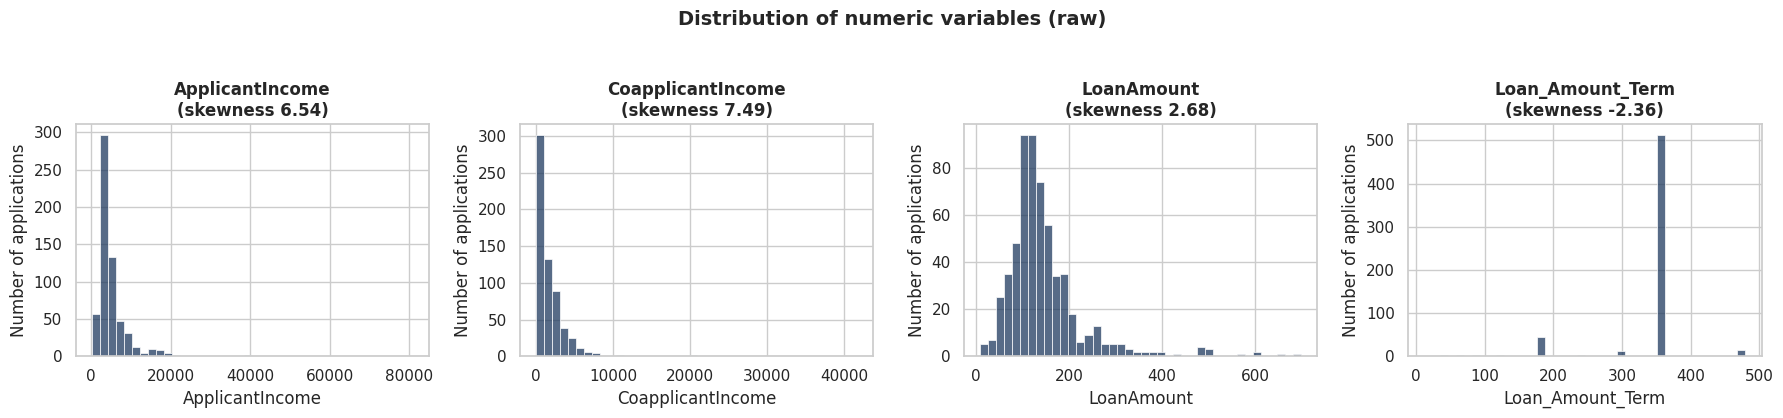

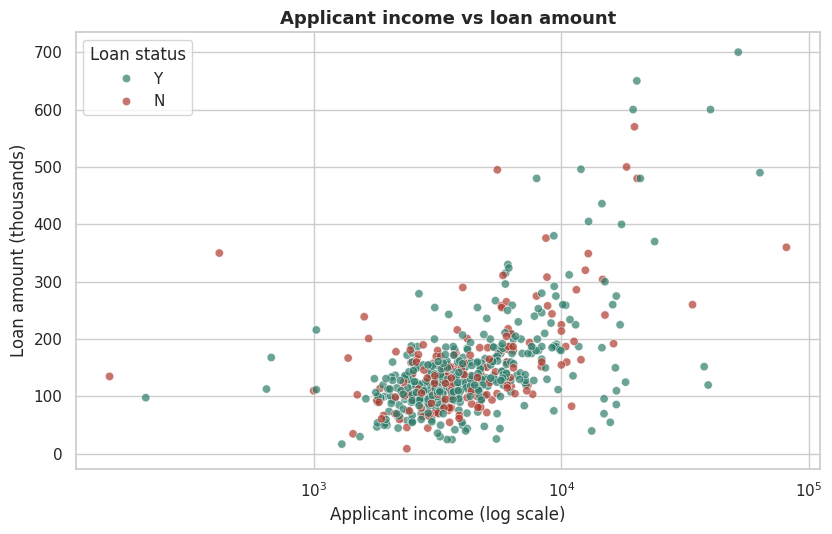

In [9]:
# Distribution of the numeric columns
num_cols = ["ApplicantIncome", "CoapplicantIncome", "LoanAmount", "Loan_Amount_Term"]
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, col in zip(axes, num_cols):
    sns.histplot(raw[col].dropna(), bins=40, color=BLUE, ax=ax)
    ax.set_title(f"{col}\n(skewness {raw[col].skew():.2f})", fontweight="bold"); ax.set_xlabel(col); ax.set_ylabel("Number of applications")
fig.suptitle("Distribution of numeric variables (raw)", fontsize=14, fontweight="bold", y=1.04)
save_fig("04_numeric_distributions_raw")

fig, ax = plt.subplots(figsize=(8.5, 5.5))
sns.scatterplot(data=raw, x="ApplicantIncome", y="LoanAmount", hue="Loan_Status", hue_order=["Y", "N"], palette=STATUS_PALETTE, alpha=.7, ax=ax)
ax.set_xscale("log"); ax.legend(title="Loan status")
ax.set_title("Applicant income vs loan amount", fontsize=13, fontweight="bold")
ax.set_xlabel("Applicant income (log scale)"); ax.set_ylabel("Loan amount (thousands)")
save_fig("05_income_vs_loan_amount")

### What the inspection shows
* **614 rows and 13 columns**, one identifier (`Loan_ID`), eleven predictors and one target.
* **Missing values** appear in 7 columns (about 22% of rows have at least one). `Credit_History` is the largest gap, with 50 missing values.
* **No duplicate records**, and every `Loan_ID` is unique.
* **The target is imbalanced:** 68.7% approved against 31.3% rejected, so plain accuracy is a weak yardstick.
* **Income and loan amount are heavily right-skewed** (skewness 2.7 to 7.5), with a few very large values.
* **Credit history is the standout pattern:** applicants whose history meets guidelines are approved about 80% of the time, against only about 8% when it does not.
* **Two columns are stored in an awkward way:** `Dependents` is text (it contains "3+") and `Credit_History` is a number that really represents a category.

## Part 3: Feature Engineering and Data Preprocessing
Each step is written as a small, reusable function. At the end they are chained into one pipeline (3.9) so the exact same steps can be applied to any new applications.

### 3.1 Data cleaning: correct data types and rename columns
* `Dependents`: text such as "3+" becomes the number 3.
* `Credit_History`: the codes 1 and 0 become the labels **Meets** (history meets guidelines) and **Fails**. Missing stays missing for now.
* Text columns are trimmed of stray spaces.
* Columns are renamed to clear `snake_case` names, and the unit is placed in the name where the data dictionary states one (`loan_amount_k` is in thousands, `loan_term_months` is in months).

In [10]:
RENAME = {
    "Loan_ID": "loan_id", "Gender": "gender", "Married": "married", "Dependents": "dependents",
    "Education": "education", "Self_Employed": "self_employed", "ApplicantIncome": "applicant_income",
    "CoapplicantIncome": "coapplicant_income", "LoanAmount": "loan_amount_k", "Loan_Amount_Term": "loan_term_months",
    "Credit_History": "credit_history", "Property_Area": "property_area", "Loan_Status": "loan_status",
}

def standardise_types(df):
    # Rename columns and correct data types. Missing values are left untouched at this stage.
    out = df.rename(columns=RENAME).copy()
    for c in ["gender", "married", "education", "self_employed", "property_area"]:
        out[c] = out[c].str.strip()
    out["dependents"] = pd.to_numeric(out["dependents"].replace({"3+": "3"}), errors="raise")
    out["credit_history"] = out["credit_history"].map({1.0: "Meets", 0.0: "Fails"})
    return out

df_all = standardise_types(raw).reset_index(drop=True)
before_after = pd.DataFrame({"before (raw)": raw.dtypes.astype(str).values, "after": df_all.dtypes.astype(str).values}, index=df_all.columns)
display(before_after)
print("dependents values:", sorted(df_all["dependents"].dropna().unique()), "| credit_history values:", df_all["credit_history"].dropna().unique().tolist())

,before (raw),after
loan_id,str,str
gender,str,str
married,str,str
dependents,str,float64
education,str,str
self_employed,str,str
applicant_income,int64,int64
coapplicant_income,float64,float64
loan_amount_k,float64,float64
loan_term_months,float64,float64


dependents values: [np.float64(0.0), np.float64(1.0), np.float64(2.0), np.float64(3.0)] | credit_history values: ['Meets', 'Fails']


### 3.2 Data cleaning: duplicates
The inspection found no duplicates. The check is repeated after the renaming and type corrections, in case an apparent difference (such as "3+" against 3) had been hiding one.

In [11]:
predictor_cols = [c for c in df_all.columns if c != "loan_id"]
n_dup = df_all.duplicated(subset=predictor_cols).sum()
df_all = df_all.drop_duplicates(subset=predictor_cols).reset_index(drop=True)
print(f"Duplicate applications found and removed: {n_dup}. Rows remaining: {len(df_all)}")

Duplicate applications found and removed: 0. Rows remaining: 614


### 3.3 Split into train and hold-out **before** fitting anything
A stratified 80/20 split keeps the approval rate the same in both parts. Every value learned from the data from here on comes from the **training part only**.

In [12]:
train_idx, hold_idx = train_test_split(df_all.index, test_size=0.20, stratify=df_all["loan_status"], random_state=RANDOM_STATE)
df_all["split"] = "train"
df_all.loc[hold_idx, "split"] = "holdout"
train_raw = df_all[df_all["split"] == "train"].copy()

split_summary = df_all.groupby("split")["loan_status"].agg(applications="count", approved=lambda s: (s == "Y").sum())
split_summary["approval_rate"] = split_summary["approved"] / split_summary["applications"]
display(split_summary)

,applications,approved,approval_rate
split,,,
holdout,123,85,0.691
train,491,337,0.686


### 3.4 Data cleaning: missing values
Each column gets the treatment that suits its meaning, not one blanket rule.

| Column | Missing | Treatment | Why |
|---|---|---|---|
| `gender`, `married`, `self_employed` | 13 / 3 / 32 | Most common value (mode) | Few values are missing and one category dominates; categories cannot have a mean. |
| `dependents` | 15 | Most common value (0) | A count where "0" is by far the most common answer. |
| `loan_amount_k` | 22 | **Median** | The amounts are heavily skewed, so the median is not pulled up by very large loans. |
| `loan_term_months` | 14 | Most common value (360) | 83% of loans have a 360-month term. |
| `credit_history` | 50 | **New category "Unknown"** | The strongest predictor in the data. Guessing the answer would invent information, and "no history on record" is a real applicant situation. Keeping it separate lets Part 4 test whether it matters. |

In [13]:
# Evidence for the credit_history decision (training rows only)
ch = train_raw.assign(credit_history=train_raw["credit_history"].fillna("Unknown"))
evidence = pd.crosstab(ch["credit_history"], ch["loan_status"]).assign(approval_rate=lambda d: d["Y"] / (d["Y"] + d["N"]))
display(evidence)
print("'Unknown' applicants are approved at a rate between the two known groups. Mixing them into 'Meets' would blur a group that behaves differently, so they get their own category.")

loan_status,N,Y,approval_rate
credit_history,,,
Fails,61,6,0.090
Meets,80,301,0.790
Unknown,13,30,0.698


'Unknown' applicants are approved at a rate between the two known groups. Mixing them into 'Meets' would blur a group that behaves differently, so they get their own category.


In [14]:
def fit_imputer(train):
    # Learn the fill values from the TRAINING rows only.
    return {
        "gender": train["gender"].mode()[0], "married": train["married"].mode()[0],
        "self_employed": train["self_employed"].mode()[0], "dependents": int(train["dependents"].mode()[0]),
        "loan_amount_k": float(train["loan_amount_k"].median()), "loan_term_months": int(train["loan_term_months"].mode()[0]),
        "credit_history": "Unknown",
    }

def impute(df, p):
    # Apply the learned fill values to any dataframe.
    out = df.copy()
    for c in ["gender", "married", "self_employed", "credit_history"]:
        out[c] = out[c].fillna(p[c])
    out["dependents"]       = out["dependents"].fillna(p["dependents"]).astype(int)
    out["loan_amount_k"]    = out["loan_amount_k"].fillna(p["loan_amount_k"])
    out["loan_term_months"] = out["loan_term_months"].fillna(p["loan_term_months"]).astype(int)
    return out

imputation_params = fit_imputer(train_raw)
print("Learned fill values:", imputation_params)

imputed_all = impute(df_all, imputation_params)
check = pd.DataFrame({"missing_before": df_all.isna().sum(), "missing_after": imputed_all.isna().sum()})
display(check[check["missing_before"] > 0])
assert imputed_all.isna().sum().sum() == 0
print("All missing values handled: 0 remain.")

Learned fill values: {'gender': 'Male', 'married': 'Yes', 'self_employed': 'No', 'dependents': 0, 'loan_amount_k': 128.0, 'loan_term_months': 360, 'credit_history': 'Unknown'}


,missing_before,missing_after
gender,13,0
married,3,0
dependents,15,0
self_employed,32,0
loan_amount_k,22,0
loan_term_months,14,0
credit_history,50,0


All missing values handled: 0 remain.


### 3.5 Feature engineering: creating new features
Features are built from lending logic: a lender cares about the **total income available**, how big the **monthly repayment** is against that income, and how many people the income supports.

| New feature | How it is built | Why it helps |
|---|---|---|
| `total_income` | applicant + co-applicant income | Repayment ability depends on household income, not one person's. |
| `has_coapplicant` | 1 if co-applicant income > 0 | 44% of applications have no co-applicant income; this flags joint applications. |
| `emi` | `loan_amount_k x 1000 / loan_term_months` | A simple monthly instalment (principal only, no interest). |
| `emi_to_income` | `emi / total_income` | The repayment burden, a standard affordability ratio. Assumes incomes are monthly (the data does not say). |
| `household_size` | 1 + married + dependents | How many people the income supports. |
| `income_per_person` | `total_income / household_size` | Income left per household member. |
| `log_applicant_income`, `log_coapplicant_income`, `log_total_income`, `log_loan_amount`, `log_income_per_person` | `log(1 + value)` | Compress the long right tail so very large values stop dominating. |

In [15]:
def engineer_features(df):
    # Create the new features. Purely arithmetic, so nothing is learned from the data.
    out = df.copy()
    out["total_income"]       = out["applicant_income"] + out["coapplicant_income"]
    out["has_coapplicant"]    = (out["coapplicant_income"] > 0).astype(int)
    out["emi"]                = out["loan_amount_k"] * 1000 / out["loan_term_months"]
    out["emi_to_income"]      = out["emi"] / out["total_income"]
    out["household_size"]     = 1 + (out["married"] == "Yes").astype(int) + out["dependents"]
    out["income_per_person"]  = out["total_income"] / out["household_size"]
    out["log_applicant_income"]   = np.log1p(out["applicant_income"])
    out["log_coapplicant_income"] = np.log1p(out["coapplicant_income"])
    out["log_total_income"]       = np.log1p(out["total_income"])
    out["log_loan_amount"]        = np.log1p(out["loan_amount_k"])
    out["log_income_per_person"]  = np.log1p(out["income_per_person"])
    return out

cleaned_all = engineer_features(imputed_all)
new_features = ["total_income", "has_coapplicant", "emi", "emi_to_income", "household_size", "income_per_person",
                "log_applicant_income", "log_coapplicant_income", "log_total_income", "log_loan_amount", "log_income_per_person"]
display(cleaned_all[new_features].describe().T)
assert np.isfinite(cleaned_all[new_features]).all().all(), "Engineered features contain inf or NaN"
print("All engineered features are finite.")

,count,mean,std,min,25%,50%,75%,max
total_income,614.000,"7,024.705","6,458.664","1,442.000","4,166.000","5,416.500","7,521.750","81,000.000"
has_coapplicant,614.000,0.555,0.497,0.000,0.000,1.000,1.000,1.000
emi,614.000,473.687,511.134,25.000,288.889,361.111,505.556,"9,250.000"
emi_to_income,614.000,0.077,0.079,0.007,0.055,0.069,0.082,1.237
household_size,614.000,2.397,1.252,1.000,1.000,2.000,3.000,5.000
income_per_person,614.000,"3,686.149","3,517.614",457.500,"1,732.250","2,744.750","4,297.750","35,673.000"
log_applicant_income,614.000,8.342,0.645,5.017,7.965,8.246,8.665,11.302
log_coapplicant_income,614.000,4.290,3.876,0.000,0.000,7.081,7.740,10.637
log_total_income,614.000,8.670,0.545,7.274,8.335,8.597,8.926,11.302
log_loan_amount,614.000,4.866,0.491,2.303,4.618,4.860,5.110,6.553


All engineered features are finite.


### 3.6 Outlier detection and treatment
Three methods are used on the **training rows**: boxplots (visual), the **IQR rule** (a value more than 1.5 x IQR beyond the quartiles) and the **z-score** (more than 3 standard deviations from the mean).

,skewness,iqr_lower,iqr_upper,outliers_iqr,pct_iqr,outliers_zscore,max_value
variable,,,,,,,
applicant_income,6.546,"-1,472.500","10,203.500",40,8.147,6,"81,000.000"
coapplicant_income,7.606,"-3,361.500","5,602.500",21,4.277,4,"41,667.000"
loan_amount_k,2.791,3.750,261.750,33,6.721,11,700.000
total_income,5.779,-883.250,"12,610.750",41,8.350,8,"81,000.000"
emi_to_income,10.889,0.017,0.120,36,7.332,3,1.237


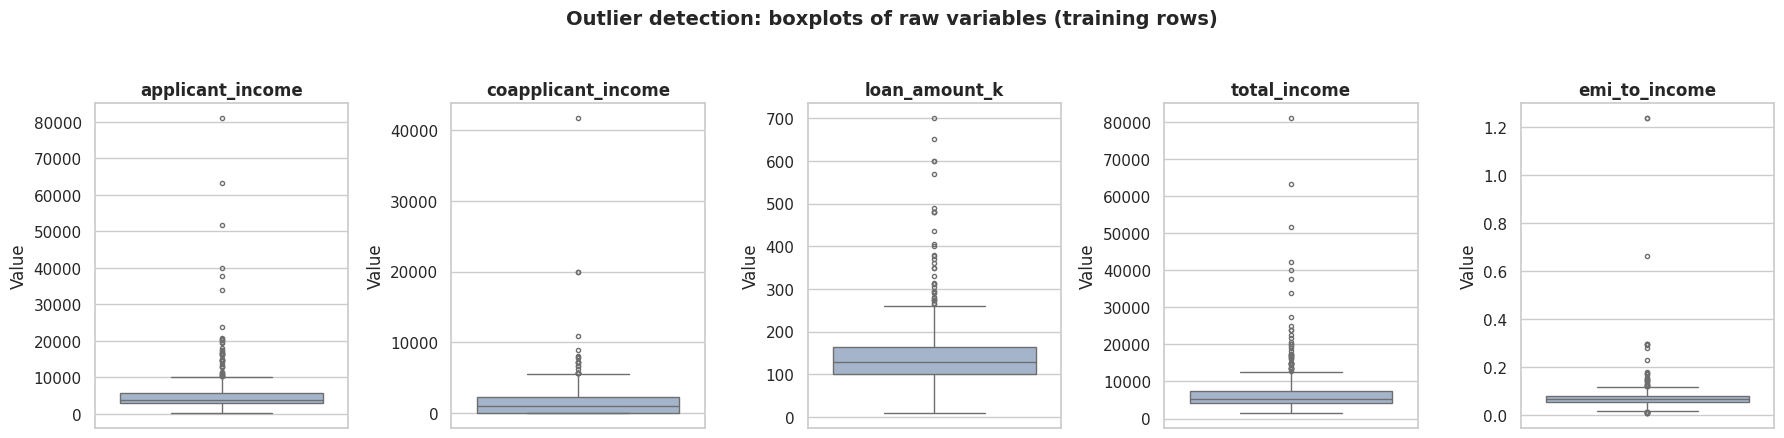

In [16]:
train_eng = cleaned_all[cleaned_all["split"] == "train"]
outlier_cols = ["applicant_income", "coapplicant_income", "loan_amount_k", "total_income", "emi_to_income"]
rows = []
for c in outlier_cols:
    s = train_eng[c]
    q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    z = (s - s.mean()) / s.std()
    rows.append({"variable": c, "skewness": s.skew(), "iqr_lower": lo, "iqr_upper": hi,
                 "outliers_iqr": int(((s < lo) | (s > hi)).sum()), "pct_iqr": 100 * ((s < lo) | (s > hi)).mean(),
                 "outliers_zscore": int((z.abs() > 3).sum()), "max_value": s.max()})
outlier_table = pd.DataFrame(rows).set_index("variable")
display(outlier_table)

fig, axes = plt.subplots(1, 5, figsize=(18, 4.2))
for ax, c in zip(axes, outlier_cols):
    sns.boxplot(y=train_eng[c], color="#9DB4D1", fliersize=3, ax=ax)
    ax.set_title(c, fontweight="bold"); ax.set_ylabel("Value"); ax.set_xlabel("")
fig.suptitle("Outlier detection: boxplots of raw variables (training rows)", fontsize=14, fontweight="bold", y=1.04)
save_fig("06_outliers_boxplots_raw")

**What the outlier checks show.** All five variables have extreme values. The IQR rule flags 4% to 8% of applications (for example 40 applicant incomes, 33 loan amounts), while the z-score flags far fewer (3 to 11). The z-score finds fewer because the extreme values themselves inflate the standard deviation, so it becomes less sensitive on skewed data. That is why the IQR rule is used for treatment. The largest applicant income is 81,000 against a 75th percentile of about 5,800. One application has a monthly instalment 124% of its total income (`emi_to_income` = 1.24), which is either a data issue or a very risky request.

**Approach.** These extreme values are **real** (a few high earners and large loans), not typing errors, and the dataset is small, so deleting rows would throw away genuine applicants and weaken the model. Instead, the treatment has two steps:
1. **Log transform** (done in 3.5) pulls the long right tail in, which fixes most of the skew.
2. **Winsorising (capping):** any remaining extreme value is limited to the IQR limits, **calculated on the training rows only**. Values are limited, not deleted.

,raw,after log
applicant_income,6.546,0.769
coapplicant_income,7.606,-0.138
loan_amount_k,2.791,-0.182
total_income,5.779,1.171
income_per_person,3.300,0.327


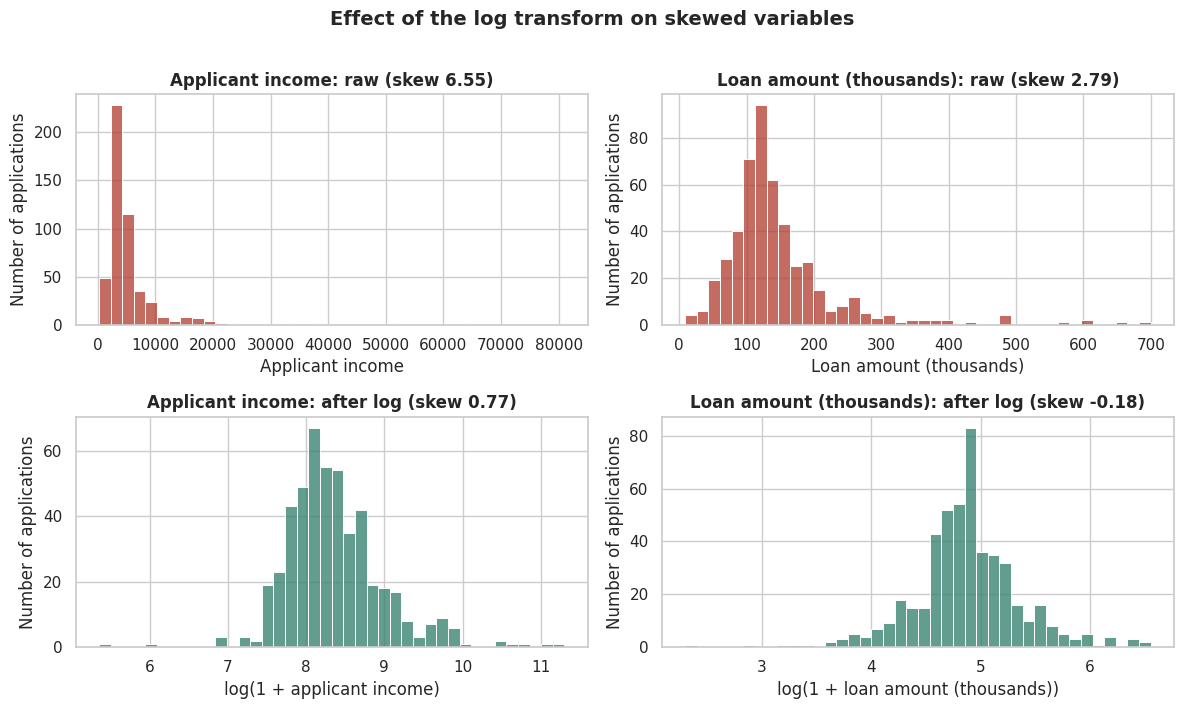

In [17]:
# Skewness before and after the log transform
skew_table = pd.DataFrame({
    "raw": [train_eng[c].skew() for c in ["applicant_income", "coapplicant_income", "loan_amount_k", "total_income", "income_per_person"]],
    "after log": [train_eng[c].skew() for c in ["log_applicant_income", "log_coapplicant_income", "log_loan_amount", "log_total_income", "log_income_per_person"]],
}, index=["applicant_income", "coapplicant_income", "loan_amount_k", "total_income", "income_per_person"])
display(skew_table)

fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for j, (raw_c, log_c, label) in enumerate([("applicant_income", "log_applicant_income", "Applicant income"), ("loan_amount_k", "log_loan_amount", "Loan amount (thousands)")]):
    sns.histplot(train_eng[raw_c], bins=40, color=RED, ax=axes[0, j]); axes[0, j].set_title(f"{label}: raw (skew {train_eng[raw_c].skew():.2f})", fontweight="bold")
    axes[0, j].set_xlabel(label); axes[0, j].set_ylabel("Number of applications")
    sns.histplot(train_eng[log_c], bins=40, color=GREEN, ax=axes[1, j]); axes[1, j].set_title(f"{label}: after log (skew {train_eng[log_c].skew():.2f})", fontweight="bold")
    axes[1, j].set_xlabel(f"log(1 + {label.lower()})"); axes[1, j].set_ylabel("Number of applications")
fig.suptitle("Effect of the log transform on skewed variables", fontsize=14, fontweight="bold", y=1.01)
save_fig("07_log_transform_effect")

The log transform pulls in the long tail and brings the skewness close to zero: applicant income **6.55 to 0.77**, co-applicant income **7.61 to -0.14**, loan amount **2.79 to -0.18**, total income **5.78 to 1.17** and income per person **3.30 to 0.33**.

,lower_limit,upper_limit,values_capped_(all_614)
log_applicant_income,6.932,9.713,27.000
log_coapplicant_income,-11.573,19.288,0.000
log_total_income,7.450,9.817,21.000
log_loan_amount,3.882,5.850,39.000
log_income_per_person,6.083,9.742,9.000
emi_to_income,0.017,0.120,51.000


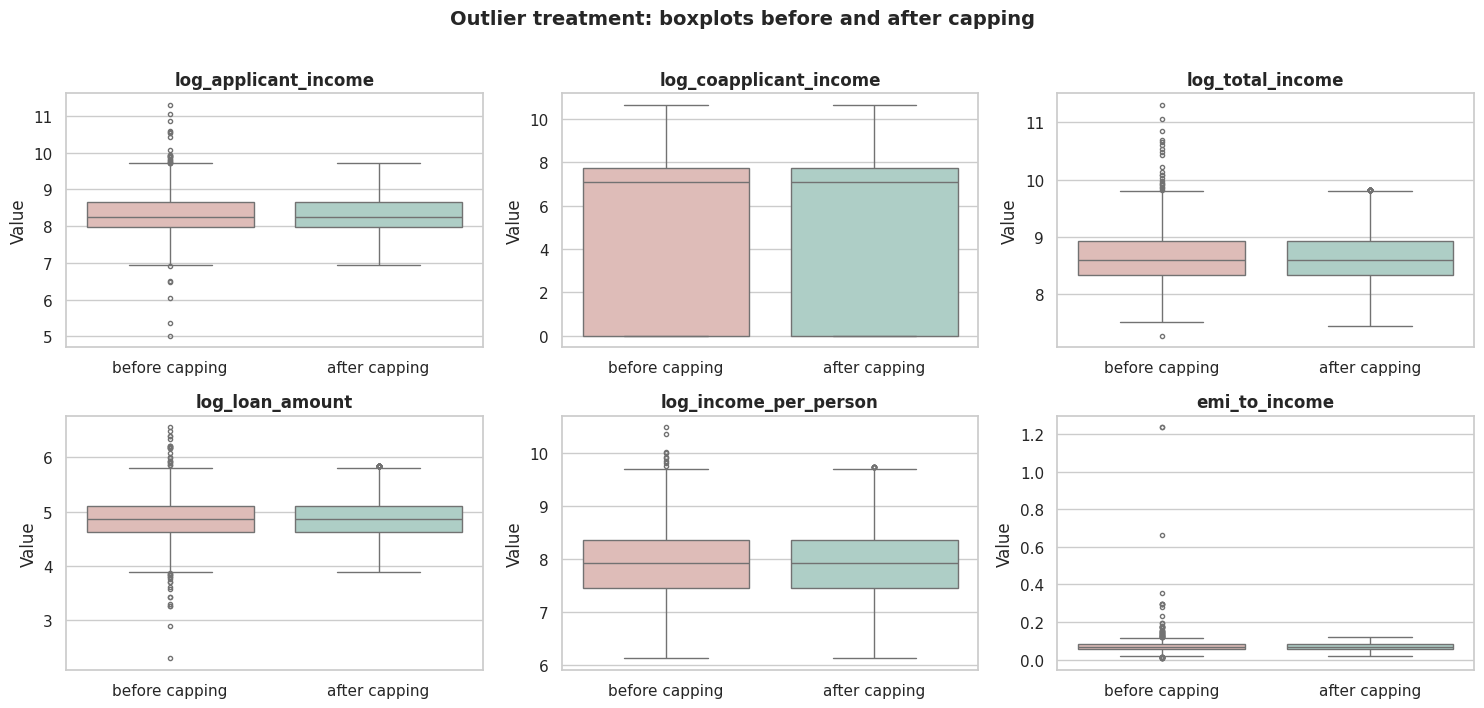

In [18]:
CAP_COLS = ["log_applicant_income", "log_coapplicant_income", "log_total_income", "log_loan_amount", "log_income_per_person", "emi_to_income"]

def fit_caps(train, cols, k=1.5):
    # IQR limits learned from the TRAINING rows only.
    caps = {}
    for c in cols:
        q1, q3 = train[c].quantile([.25, .75]); iqr = q3 - q1
        caps[c] = [float(q1 - k * iqr), float(q3 + k * iqr)]
    return caps

def apply_caps(df, caps):
    out = df.copy()
    for c, (lo, hi) in caps.items():
        out[c] = out[c].clip(lower=lo, upper=hi)
    return out

caps = fit_caps(train_eng, CAP_COLS)
capped_all = apply_caps(cleaned_all, caps)
n_capped = pd.DataFrame({c: {"lower_limit": caps[c][0], "upper_limit": caps[c][1],
                             "values_capped_(all_614)": int((cleaned_all[c] != capped_all[c]).sum())} for c in CAP_COLS}).T
display(n_capped)

fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, c in zip(axes.ravel(), CAP_COLS):
    plot_df = pd.concat([pd.DataFrame({"value": cleaned_all[c], "stage": "before capping"}), pd.DataFrame({"value": capped_all[c], "stage": "after capping"})])
    sns.boxplot(data=plot_df, x="stage", y="value", hue="stage", palette={"before capping": "#E4B7B2", "after capping": "#A9D3C8"}, legend=False, fliersize=3, ax=ax)
    ax.set_title(c, fontweight="bold"); ax.set_xlabel(""); ax.set_ylabel("Value")
fig.suptitle("Outlier treatment: boxplots before and after capping", fontsize=14, fontweight="bold", y=1.01)
save_fig("08_outliers_after_capping")

Capping limited **27** applicant-income values, **21** total-income values, **39** loan amounts, **9** income-per-person values and **51** `emi_to_income` values (counted across all 614 rows). Nothing was capped for `log_coapplicant_income`: 44% of its values are zero, which makes its IQR very wide. That feature is not used in the final dataset. **No rows were deleted**, so all 614 applications are kept.

### 3.7 Feature encoding
Models need numbers. The right technique depends on what the column *means*:

| Column | Type | Technique | Why |
|---|---|---|---|
| `loan_status` (target) | 2 classes | **Label encoding**: N = 0, Y = 1 | A target only needs two numbers. |
| `gender`, `married`, `education`, `self_employed` | 2 categories | **Label (binary) encoding** 0/1 | With two categories, one 0/1 column holds all the information. One-hot would only add a duplicate column. |
| `property_area` | 3 categories, **no order** | **One-hot encoding** (Rural is the reference) | Label codes 0/1/2 would tell a model that Urban is "twice" Semiurban, which is false. |
| `credit_history` | 3 categories (Meets, Fails, Unknown), **no order** | **One-hot encoding** (Meets is the reference) | Keeps "Unknown" as its own signal. |
| `dependents` | 0, 1, 2, 3 | Kept as an **ordinal number** | The order is real: 3 dependents means more than 1. |

One category per variable is dropped as the *reference*, because the remaining columns already imply it. Keeping all of them would make the columns perfectly redundant (the "dummy variable trap") and cause problems for linear models.

In [19]:
BINARY_MAPS = {"gender": {"Female": 0, "Male": 1}, "married": {"No": 0, "Yes": 1},
               "education": {"Not Graduate": 0, "Graduate": 1}, "self_employed": {"No": 0, "Yes": 1}}
PROPERTY_LEVELS = ["Rural", "Semiurban", "Urban"]          # reference level: Rural
CREDIT_LEVELS   = ["Meets", "Fails", "Unknown"]            # reference level: Meets

def encode_features(df):
    # Turn categories into numbers. The category lists are fixed, so nothing is learned from the data.
    out = df.copy()
    for col, mapping in BINARY_MAPS.items():
        out[col] = out[col].map(mapping)
    for lvl in PROPERTY_LEVELS[1:]:
        out[f"property_area_{lvl}"] = (df["property_area"] == lvl).astype(int)
    for lvl in CREDIT_LEVELS[1:]:
        out[f"credit_history_{lvl}"] = (df["credit_history"] == lvl).astype(int)
    out = out.drop(columns=["property_area", "credit_history"])
    if "loan_status" in out.columns:
        out["loan_approved"] = out["loan_status"].map({"N": 0, "Y": 1})
    assert out[list(BINARY_MAPS)].notna().all().all(), "An unexpected category was found"
    return out

encoded_all = encode_features(capped_all)
display(encoded_all[["gender", "married", "education", "self_employed", "dependents", "property_area_Semiurban", "property_area_Urban",
                     "credit_history_Fails", "credit_history_Unknown", "loan_approved"]].head(8))
print("Target encoding check:", encoded_all.groupby("loan_status")["loan_approved"].first().to_dict())

,gender,married,education,self_employed,dependents,property_area_Semiurban,property_area_Urban,credit_history_Fails,credit_history_Unknown,loan_approved
0,1,0,1,0,0,0,1,0,0,1
1,1,1,1,0,1,0,0,0,0,0
2,1,1,1,1,0,0,1,0,0,1
3,1,1,0,0,0,0,1,0,0,1
4,1,0,1,0,0,0,1,0,0,1
5,1,1,1,1,2,0,1,0,0,1
6,1,1,0,0,0,0,1,0,0,1
7,1,1,1,0,3,1,0,1,0,0


Target encoding check: {'N': 0, 'Y': 1}


### 3.8 Feature scaling
Features measured on very different scales (income in thousands, ratios below 1) can mislead distance-based and gradient-based models. Three scalers are compared on **total income**, first raw and then after the log transform and capping.

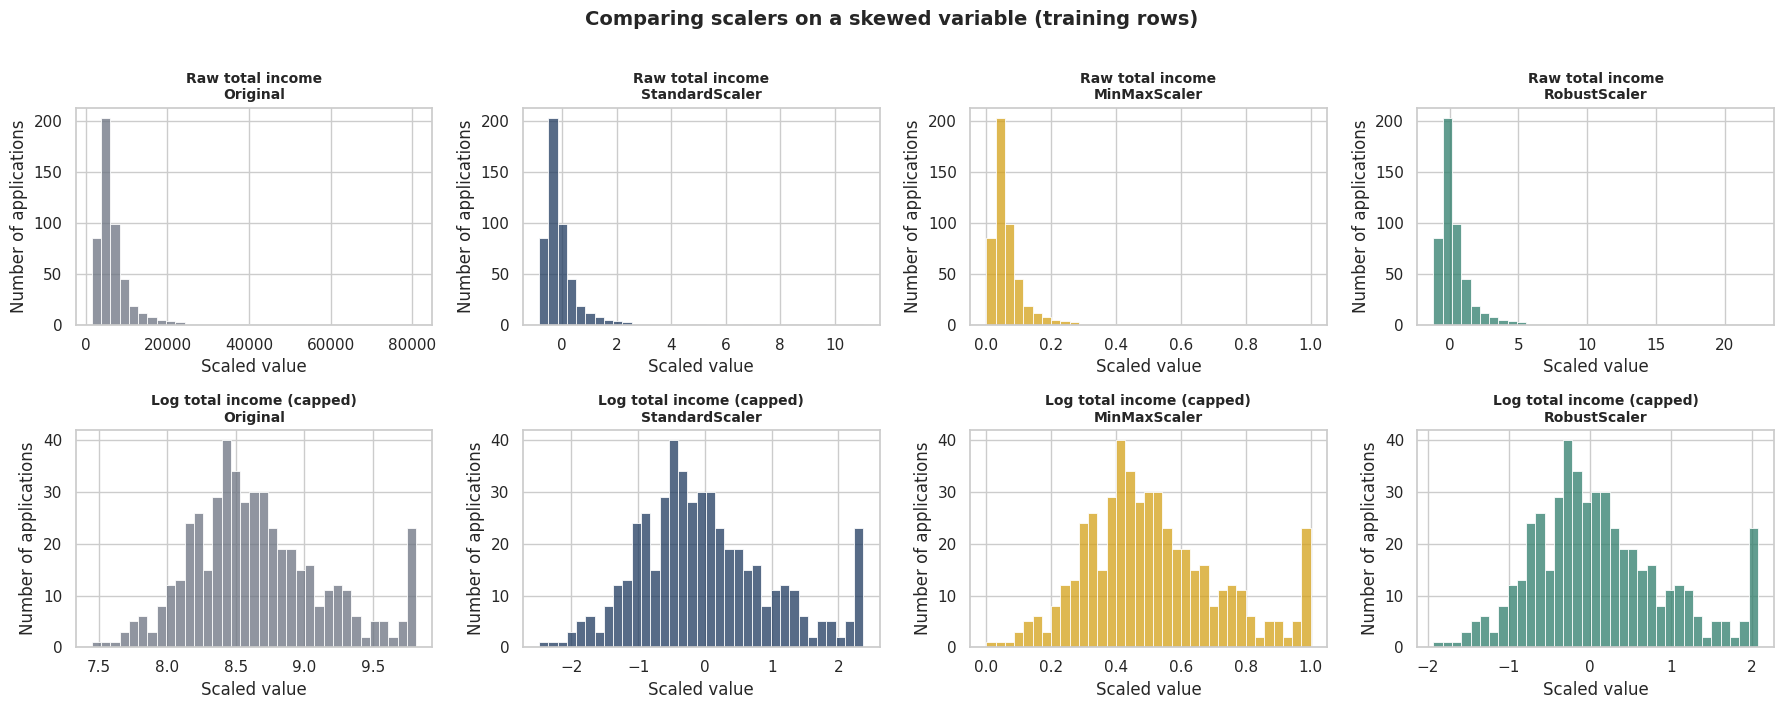

min        max      mean       std  skew
feature          scaler                                                       
total_income     Original       1,442.000 81,000.000 7,099.535 6,685.939 5.761
                 StandardScaler    -0.846     11.053     0.000     1.000 5.761
                 MinMaxScaler       0.000      1.000     0.071     0.084 5.761
                 RobustScaler      -1.171     22.413     0.506     1.982 5.761
log_total_income Original           7.450      9.817     8.661     0.488 0.545
                 StandardScaler    -2.484      2.373    -0.000     1.000 0.545
                 MinMaxScaler       0.000      1.000     0.511     0.206 0.545
                 RobustScaler      -1.931      2.069     0.115     0.824 0.545

In [20]:
train_enc = encoded_all[encoded_all["split"] == "train"]
scalers = {"Original": None, "StandardScaler": StandardScaler(), "MinMaxScaler": MinMaxScaler(), "RobustScaler": RobustScaler()}
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
summary = []
for r, (col, row_label) in enumerate([("total_income", "Raw total income"), ("log_total_income", "Log total income (capped)")]):
    values = train_enc[[col]]
    for c, (name, sc) in enumerate(scalers.items()):
        scaled = values.values.ravel() if sc is None else sc.fit_transform(values).ravel()
        sns.histplot(scaled, bins=35, color=[GREY, BLUE, GOLD, GREEN][c], ax=axes[r, c])
        axes[r, c].set_title(f"{row_label}\n{name}", fontweight="bold", fontsize=10)
        axes[r, c].set_xlabel("Scaled value"); axes[r, c].set_ylabel("Number of applications")
        summary.append({"feature": col, "scaler": name, "min": scaled.min(), "max": scaled.max(), "mean": scaled.mean(), "std": scaled.std(), "skew": stats.skew(scaled)})
fig.suptitle("Comparing scalers on a skewed variable (training rows)", fontsize=14, fontweight="bold", y=1.01)
save_fig("09_scaler_comparison")
display(pd.DataFrame(summary).set_index(["feature", "scaler"]))

**What the comparison shows.** On raw total income, none of the scalers fix the skew (it stays at 5.76), because scaling changes the *range* and not the *shape*. `MinMaxScaler` squeezes most applicants below 0.1 (mean 0.07) because one huge income sets the range. `StandardScaler` and `RobustScaler` still leave a maximum of 11 and 22 standard-deviation-like units. This is why the log transform and capping come **first**. After them, the skew drops to 0.55 and the values sit in a tidy range of about -2.5 to 2.4.

**Choice: `StandardScaler` for the continuous features.** After the log transform and capping, the continuous features are roughly symmetric with no extreme values left. `StandardScaler` (mean 0, spread 1) therefore works well, and it suits the models most likely to be used next (logistic regression, SVM, k-nearest neighbours). `MinMaxScaler` would squeeze most values into a narrow band because one extreme value sets the range. `RobustScaler` is a better choice if outliers had been left in, but they have already been handled. The 0/1 columns are **not** scaled, since they are already on a common scale. Tree-based models do not need scaling, and scaled data does them no harm.

The scaler is fitted on the **training rows only**.

In [21]:
CONT_FEATURES = ["log_applicant_income", "log_coapplicant_income", "log_total_income", "log_loan_amount", "log_income_per_person",
                 "emi_to_income", "loan_term_months", "household_size", "dependents"]
scaler = StandardScaler().fit(train_enc[CONT_FEATURES])          # learned from training rows only
print("Scaler learned means:", dict(zip(CONT_FEATURES, scaler.mean_.round(3))))

scaled_all = encoded_all.copy()
scaled_all[CONT_FEATURES] = scaler.transform(encoded_all[CONT_FEATURES])

check = scaled_all.groupby("split")[CONT_FEATURES].agg(["mean", "std"]).T.unstack(0)
display(check.round(3))
print("Training rows: mean = 0 and spread = 1 by construction. Hold-out rows are close but not exactly 0 and 1, which proves the hold-out was NOT used to fit the scaler.")

Scaler learned means: {'log_applicant_income': np.float64(8.35), 'log_coapplicant_income': np.float64(4.214), 'log_total_income': np.float64(8.661), 'log_loan_amount': np.float64(4.87), 'log_income_per_person': np.float64(7.94), 'emi_to_income': np.float64(0.069), 'loan_term_months': np.float64(341.743), 'household_size': np.float64(2.405), 'dependents': np.float64(0.749)}


split              holdout                                                                                                                                                       train  \
      log_applicant_income log_coapplicant_income log_total_income log_loan_amount log_income_per_person emi_to_income loan_term_months household_size dependents log_applicant_income   
mean                -0.128                  0.098           -0.076          -0.041                -0.037         0.096            0.051         -0.032     -0.026               -0.000   
std                  1.026                  0.999            1.057           0.986                 0.997         1.143            0.951          1.024      1.041                1.001   

split                                                                                                                                         
      log_coapplicant_income log_total_income log_loan_amount log_income_per_person emi_to_income loan_term_months household_size dependents  
mean                  -0.000           -0.000          -0.000                -0.000         0.000           -0.000          0.000      0.000  
std                    1.001            1.001           1.001                 1.001         1.001            1.001          1.001      1.001

Training rows: mean = 0 and spread = 1 by construction. Hold-out rows are close but not exactly 0 and 1, which proves the hold-out was NOT used to fit the scaler.


### 3.9 The full preprocessing pipeline in one function
Everything above chained together. The *fitted* values (fill values, capping limits, scaler) are kept in `PARAMS` and saved to JSON, so the pipeline can transform any new applications in exactly the same way.

In [22]:
PARAMS = {"imputation": imputation_params, "caps": caps}

def run_pipeline(df_standardised, params, fitted_scaler):
    # raw (type-corrected) data -> cleaned dataset (readable) and fully scaled/encoded dataset
    cleaned = engineer_features(impute(df_standardised, params["imputation"]))
    encoded = encode_features(apply_caps(cleaned, params["caps"]))
    scaled = encoded.copy()
    scaled[CONT_FEATURES] = fitted_scaler.transform(encoded[CONT_FEATURES])
    return cleaned, scaled

cleaned_check, scaled_check = run_pipeline(standardise_types(raw).reset_index(drop=True).assign(split=df_all["split"]), PARAMS, scaler)
assert scaled_check.equals(scaled_all) and cleaned_check.equals(cleaned_all), "Pipeline output differs from the step-by-step result"
print("Pipeline check passed: the one-function pipeline reproduces the step-by-step result exactly.")

Pipeline check passed: the one-function pipeline reproduces the step-by-step result exactly.


## Part 4: Feature Selection
Feature selection removes columns that add noise, duplicate each other or create risk, so the model learns from the information that matters. All statistics here use the **training rows only**.

Candidate features: the 24 columns produced by engineering and encoding. Three kinds of evidence are gathered:
1. **Correlation** (heatmap) to find *redundant* features that carry the same information.
2. **Relationship with the target:** correlation, **mutual information** (captures non-linear links) and a statistical test.
3. **Random forest importance:** how much a tree model relies on each feature.

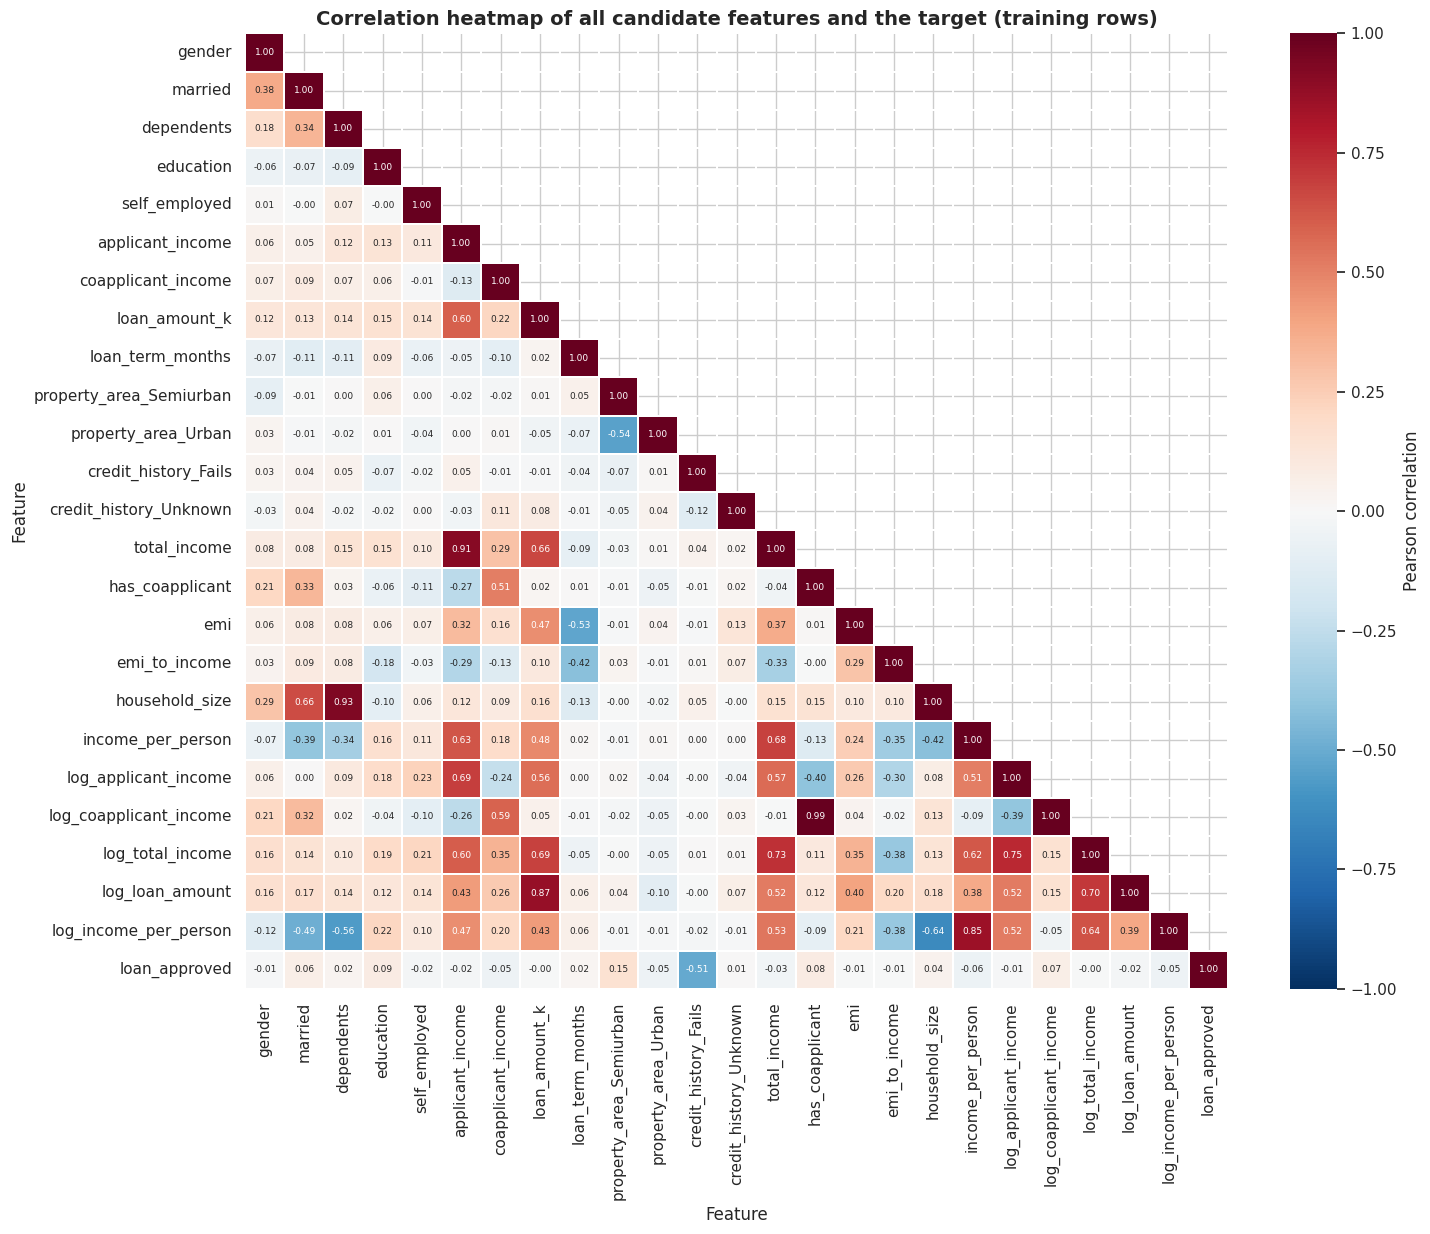

In [23]:
CANDIDATES = ["gender", "married", "dependents", "education", "self_employed",
              "applicant_income", "coapplicant_income", "loan_amount_k", "loan_term_months",
              "property_area_Semiurban", "property_area_Urban", "credit_history_Fails", "credit_history_Unknown",
              "total_income", "has_coapplicant", "emi", "emi_to_income", "household_size", "income_per_person",
              "log_applicant_income", "log_coapplicant_income", "log_total_income", "log_loan_amount", "log_income_per_person"]
DISCRETE = ["gender", "married", "dependents", "education", "self_employed", "property_area_Semiurban", "property_area_Urban",
            "credit_history_Fails", "credit_history_Unknown", "has_coapplicant", "household_size", "loan_term_months"]
BINARY = ["gender", "married", "education", "self_employed", "property_area_Semiurban", "property_area_Urban",
          "credit_history_Fails", "credit_history_Unknown", "has_coapplicant"]

train_s = scaled_all[scaled_all["split"] == "train"]
X_tr, y_tr = train_s[CANDIDATES], train_s["loan_approved"]

corr = train_s[CANDIDATES + ["loan_approved"]].corr()
fig, ax = plt.subplots(figsize=(15, 12.5))
sns.heatmap(corr, mask=np.triu(np.ones_like(corr, dtype=bool), k=1), annot=True, fmt=".2f", annot_kws={"size": 6.5}, cmap="RdBu_r", center=0,
            vmin=-1, vmax=1, linewidths=.3, cbar_kws={"label": "Pearson correlation"}, ax=ax)
ax.set_title("Correlation heatmap of all candidate features and the target (training rows)", fontsize=14, fontweight="bold")
ax.set_xlabel("Feature"); ax.set_ylabel("Feature")
save_fig("10_correlation_heatmap_all_features")

In [24]:
# Highly correlated pairs (|r| >= 0.80) = redundant information
pairs = corr.loc[CANDIDATES, CANDIDATES].where(np.tril(np.ones((len(CANDIDATES),) * 2), k=-1).astype(bool)).stack().reset_index()
pairs.columns = ["feature_1", "feature_2", "r"]
high_pairs = pairs[pairs["r"].abs() >= 0.80].sort_values("r", key=abs, ascending=False)
print(f"{len(high_pairs)} pairs of candidate features have |correlation| >= 0.80:")
display(high_pairs)

5 pairs of candidate features have |correlation| >= 0.80:


,feature_1,feature_2,r
494,log_coapplicant_income,has_coapplicant,0.992
410,household_size,dependents,0.934
317,total_income,applicant_income,0.911
535,log_loan_amount,loan_amount_k,0.869
570,log_income_per_person,income_per_person,0.853


**Redundant pairs.** The five pairs above carry the same information twice:
* `log_coapplicant_income` and `has_coapplicant` (r = 0.99): the second is simply "co-applicant income is above zero".
* `household_size` and `dependents` (0.93): household size is built from dependents.
* Three raw-versus-log pairs (`total_income` and `applicant_income` 0.91, `loan_amount_k` and `log_loan_amount` 0.87, `income_per_person` and `log_income_per_person` 0.85): the same quantity on two scales.

Random-noise probes scored a random forest importance of 0.059 (continuous) and 0.009 (0/1).


,corr_with_target,mutual_info,rf_importance,p_value,rf_vs_noise
credit_history_Fails,-0.511,0.127,0.242,0.000,25.745
emi_to_income,-0.005,0.000,0.075,0.457,1.268
income_per_person,-0.058,0.000,0.063,0.340,1.075
log_applicant_income,-0.014,0.000,0.062,0.468,1.049
applicant_income,-0.016,0.000,0.059,0.463,0.996
total_income,-0.035,0.000,0.058,0.843,0.987
log_income_per_person,-0.050,0.000,0.058,0.341,0.983
log_total_income,-0.002,0.000,0.057,0.845,0.960
emi,-0.007,0.000,0.055,0.478,0.941
loan_amount_k,-0.004,0.000,0.055,0.791,0.935


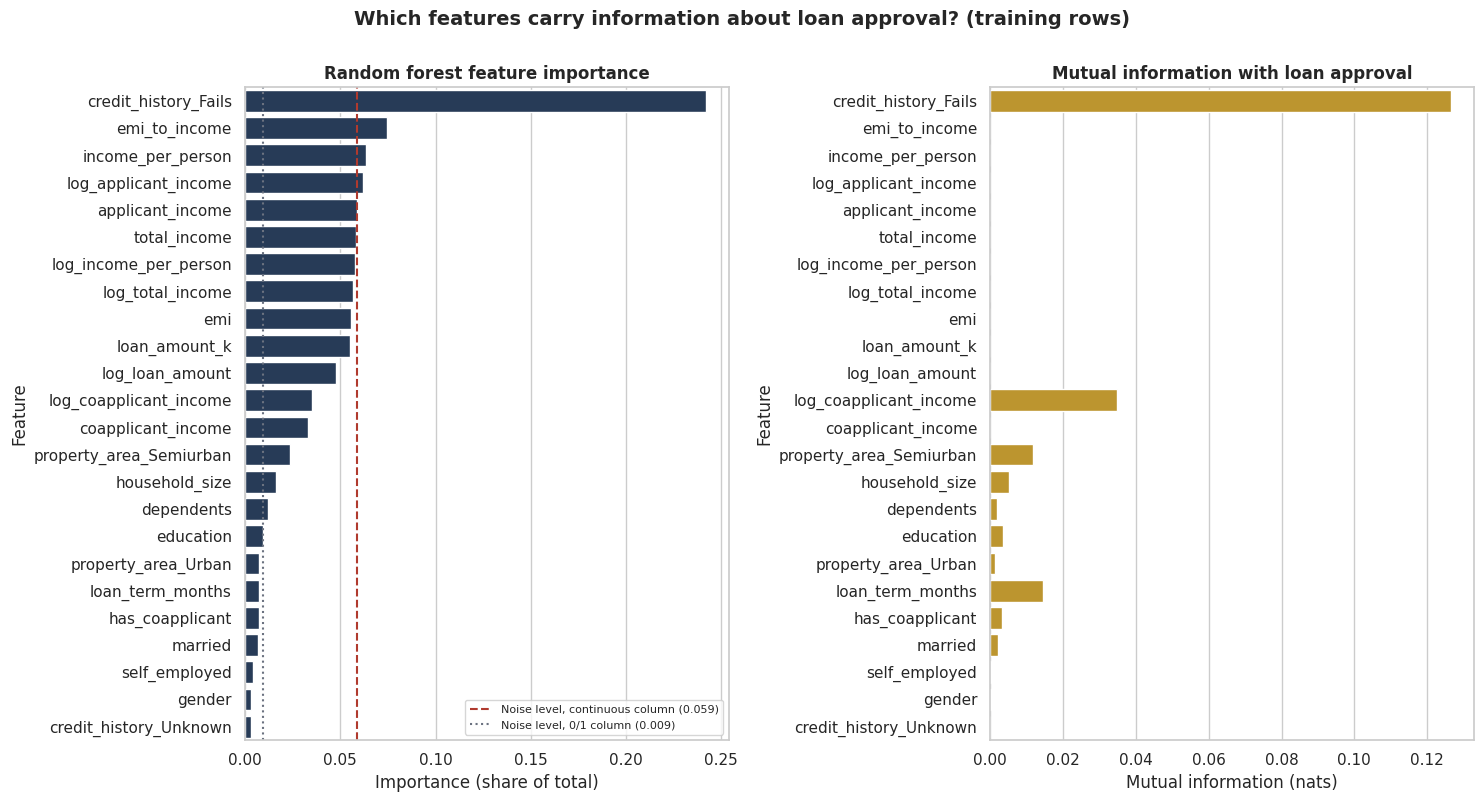

In [25]:
# Relationship of every candidate with the target
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    mi = mutual_info_classif(X_tr, y_tr, discrete_features=[c in DISCRETE for c in CANDIDATES], random_state=RANDOM_STATE)
rf = RandomForestClassifier(n_estimators=500, min_samples_leaf=5, class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1).fit(X_tr, y_tr)

# Noise probes: random columns that carry NO information. A genuinely useful feature should beat them.
# (Random forest importance is known to favour continuous columns, so it needs this yardstick.)
probe_cont, probe_bin = [], []
for seed in range(10):
    r = np.random.RandomState(seed)
    Xp = X_tr.assign(probe_cont=r.normal(size=len(X_tr)), probe_bin=r.binomial(1, 0.5, size=len(X_tr)))
    rfp = RandomForestClassifier(n_estimators=300, min_samples_leaf=5, class_weight="balanced", random_state=seed, n_jobs=-1).fit(Xp, y_tr)
    imp = pd.Series(rfp.feature_importances_, index=Xp.columns)
    probe_cont.append(imp["probe_cont"]); probe_bin.append(imp["probe_bin"])
PROBE_CONT, PROBE_BIN = float(np.mean(probe_cont)), float(np.mean(probe_bin))
print(f"Random-noise probes scored a random forest importance of {PROBE_CONT:.3f} (continuous) and {PROBE_BIN:.3f} (0/1).")

def univariate_p(col):
    # chi-square for 0/1 features, Mann-Whitney U for the rest
    if col in BINARY:
        return stats.chi2_contingency(pd.crosstab(X_tr[col], y_tr))[1]
    return stats.mannwhitneyu(X_tr.loc[y_tr == 1, col], X_tr.loc[y_tr == 0, col])[1]

signal = pd.DataFrame({"corr_with_target": X_tr.apply(lambda s: s.corr(y_tr)), "mutual_info": mi,
                       "rf_importance": rf.feature_importances_, "p_value": [univariate_p(c) for c in CANDIDATES]}, index=CANDIDATES)
signal["rf_vs_noise"] = [signal.loc[c, "rf_importance"] / (PROBE_BIN if c in BINARY else PROBE_CONT) for c in CANDIDATES]
signal = signal.sort_values("rf_importance", ascending=False)
display(signal)

fig, axes = plt.subplots(1, 2, figsize=(15, 8))
order = signal.index
sns.barplot(x=signal["rf_importance"], y=order, color=BLUE, ax=axes[0])
axes[0].axvline(PROBE_CONT, ls="--", color=RED, label=f"Noise level, continuous column ({PROBE_CONT:.3f})")
axes[0].axvline(PROBE_BIN, ls=":", color=GREY, label=f"Noise level, 0/1 column ({PROBE_BIN:.3f})")
axes[0].legend(loc="lower right", fontsize=8)
axes[0].set_title("Random forest feature importance", fontweight="bold"); axes[0].set_xlabel("Importance (share of total)"); axes[0].set_ylabel("Feature")
sns.barplot(x=signal["mutual_info"], y=order, color=GOLD, ax=axes[1])
axes[1].set_title("Mutual information with loan approval", fontweight="bold"); axes[1].set_xlabel("Mutual information (nats)"); axes[1].set_ylabel("Feature")
fig.suptitle("Which features carry information about loan approval? (training rows)", fontsize=14, fontweight="bold", y=1.0)
save_fig("11_feature_importance")

### Reading the evidence
* **Only three features show a statistically supported link with approval:** `credit_history_Fails` (by far the strongest), `property_area_Semiurban` and, more weakly, `education`.
* **Every income and loan-amount feature sits at the noise level.** Their random forest importance (0.05 to 0.07) is no higher than a column of pure random numbers (about 0.06), and their mutual information and correlation with the target are essentially zero. On their own, these features do not separate approved from rejected applications in this sample.
* That does **not** mean income is irrelevant to lending. Affordability is the core of any credit decision, so these features are treated separately below, with the reasoning written down.

One more check is needed. `credit_history_Unknown` looks weak overall, so is "Unknown" genuinely different from "Meets"?

In [26]:
meets_or_unknown = train_s[train_s["credit_history_Fails"] == 0]
ct = pd.crosstab(meets_or_unknown["credit_history_Unknown"].map({0: "Meets", 1: "Unknown"}), meets_or_unknown["loan_approved"].map({0: "Rejected", 1: "Approved"}))
ct["approval_rate"] = ct["Approved"] / (ct["Approved"] + ct["Rejected"])
display(ct)
print(f"Fisher exact test, Unknown vs Meets: p = {stats.fisher_exact(ct[['Rejected', 'Approved']].values)[1]:.3f}")
print("Unknown applicants are approved a little less often (70% vs 79%), but with only 43 of them the difference is not statistically significant.")

loan_approved,Approved,Rejected,approval_rate
credit_history_Unknown,,,
Meets,301,80,0.790
Unknown,30,13,0.698


Fisher exact test, Unknown vs Meets: p = 0.175
Unknown applicants are approved a little less often (70% vs 79%), but with only 43 of them the difference is not statistically significant.


### Selection rules
Applied in this order, with the reason recorded for every feature:

1. **Raw skewed money columns are superseded** by their capped log versions (and `emi_to_income` supersedes the raw `emi`): `applicant_income`, `coapplicant_income`, `loan_amount_k`, `total_income`, `income_per_person`, `emi`.
2. **Redundancy:** if two remaining features are correlated at **|r| >= 0.80**, the one with the **lower mutual information** with the target is removed.
3. **Fairness override:** `gender` and `married` are excluded. Using gender or marital status in credit decisions can discriminate, and many jurisdictions restrict both. Neither is statistically supported here (p = 0.84 and p = 0.18), so nothing is lost.
4. **Evidence screen:** a feature is kept as *evidence-supported* if its relationship with approval has **p < 0.10**.
5. **Domain-essential override:** four features are kept even though the sample evidence is weak, because removing them would be a business risk. This list was set from lending logic *before* looking at the results:
   * `log_total_income` (repayment capacity), `log_loan_amount` (size of the request) and `emi_to_income` (repayment burden), the three affordability measures. They may matter in combination, and 491 training rows is a small sample for detecting weak effects.
   * `credit_history_Unknown` (applicants with no credit record). Dropping it would silently score them as having a good history, the riskier assumption.
6. **Group integrity:** if one category of a variable is kept, all its one-hot columns are kept, so no category is silently merged into the reference.

Everything else is removed.

In [27]:
EVIDENCE_P, REDUNDANCY_R = 0.10, 0.80
SUPERSEDED = {"applicant_income": "log_applicant_income", "coapplicant_income": "log_coapplicant_income", "loan_amount_k": "log_loan_amount",
              "total_income": "log_total_income", "income_per_person": "log_income_per_person", "emi": "emi_to_income"}
FAIRNESS = {"gender": "Removed: protected attribute (fairness/legal risk); also statistically weak",
            "married": "Removed: protected attribute (fairness/legal risk); also statistically weak"}
DOMAIN_ESSENTIAL = {"log_total_income": "affordability: repayment capacity", "log_loan_amount": "affordability: size of the request",
                    "emi_to_income": "affordability: repayment burden", "credit_history_Unknown": "applicants with no credit record"}
GROUPS = {"property_area": ["property_area_Semiurban", "property_area_Urban"], "credit_history": ["credit_history_Fails", "credit_history_Unknown"]}

decisions, remaining = {}, list(CANDIDATES)

# Rule 1: superseded raw columns
for raw_col, better in SUPERSEDED.items():
    decisions[raw_col] = f"Removed: skewed raw version, replaced by {better}"; remaining.remove(raw_col)

# Rule 2: redundancy, always dropping the weaker of a highly correlated pair
rem_corr = X_tr[remaining].corr().abs()
while True:
    sub = rem_corr.loc[remaining, remaining].where(np.tril(np.ones((len(remaining),) * 2), k=-1).astype(bool)).stack()
    sub = sub[sub >= REDUNDANCY_R]
    if sub.empty:
        break
    a, b = sub.idxmax()
    weaker, stronger = (a, b) if signal.loc[a, "mutual_info"] < signal.loc[b, "mutual_info"] else (b, a)
    decisions[weaker] = f"Removed: redundant with {stronger} (|r| = {sub.max():.2f}) and weaker signal"; remaining.remove(weaker)

# Rule 3: fairness override
for c, why in FAIRNESS.items():
    if c in remaining:
        decisions[c] = why; remaining.remove(c)

# Rules 4 to 6: keep evidence-supported features, domain-essential features and whole one-hot groups
keep = {c: f"KEPT: evidence (p = {signal.loc[c, 'p_value']:.3f})" for c in remaining if signal.loc[c, "p_value"] < EVIDENCE_P}
for c, why in DOMAIN_ESSENTIAL.items():
    if c in remaining and c not in keep:
        keep[c] = f"KEPT: domain-essential ({why})"
for grp, cols in GROUPS.items():
    if any(c in keep for c in cols):
        for c in cols:
            if c in remaining and c not in keep:
                keep[c] = f"KEPT: keeps every category of {grp}"
for c in remaining:
    if c not in keep:
        decisions[c] = f"Removed: no supported link with approval (p = {signal.loc[c, 'p_value']:.2f}) and not domain-essential"
decisions.update(keep)

selection = signal.assign(decision=pd.Series(decisions)).sort_values(["decision", "rf_importance"], ascending=[False, False])
display(selection[["corr_with_target", "mutual_info", "rf_importance", "rf_vs_noise", "p_value", "decision"]])
FINAL_FEATURES = [c for c in CANDIDATES if decisions[c].startswith("KEPT")]
EVIDENCE_ONLY = [c for c in CANDIDATES if decisions[c].startswith("KEPT: evidence")]
print(f"\nKept {len(FINAL_FEATURES)} of {len(CANDIDATES)} candidate features:\n{FINAL_FEATURES}")
selection.to_csv(PROC_DIR / "feature_selection_summary.csv")

,corr_with_target,mutual_info,rf_importance,rf_vs_noise,p_value,decision
total_income,-0.035,0.000,0.058,0.987,0.843,"Removed: skewed raw version, replaced by log_t..."
loan_amount_k,-0.004,0.000,0.055,0.935,0.791,"Removed: skewed raw version, replaced by log_l..."
income_per_person,-0.058,0.000,0.063,1.075,0.340,"Removed: skewed raw version, replaced by log_i..."
coapplicant_income,-0.047,0.000,0.033,0.562,0.466,"Removed: skewed raw version, replaced by log_c..."
applicant_income,-0.016,0.000,0.059,0.996,0.463,"Removed: skewed raw version, replaced by log_a..."
emi,-0.007,0.000,0.055,0.941,0.478,"Removed: skewed raw version, replaced by emi_t..."
has_coapplicant,0.080,0.003,0.007,0.749,0.095,Removed: redundant with log_coapplicant_income...
dependents,0.024,0.002,0.012,0.201,0.609,Removed: redundant with household_size (|r| = ...
married,0.065,0.002,0.007,0.720,0.184,Removed: protected attribute (fairness/legal r...
gender,-0.015,0.000,0.003,0.349,0.841,Removed: protected attribute (fairness/legal r...



Kept 8 of 24 candidate features:
['education', 'property_area_Semiurban', 'property_area_Urban', 'credit_history_Fails', 'credit_history_Unknown', 'emi_to_income', 'log_total_income', 'log_loan_amount']


### Selection result: 8 of 24 features kept

| Kept feature | Why |
|---|---|
| `credit_history_Fails` | By far the strongest signal (correlation -0.51, p < 0.001, importance about 26 times the noise level). |
| `property_area_Semiurban` | Statistically supported (p = 0.001); semi-urban applicants are approved more often. |
| `education` | Weaker but supported (p = 0.074). |
| `property_area_Urban` | Kept with `property_area_Semiurban` so that no category is silently merged into the reference. |
| `log_total_income`, `log_loan_amount`, `emi_to_income` | Domain-essential affordability measures (capacity, request, burden). Weak sample evidence, kept on lending logic. |
| `credit_history_Unknown` | Domain-essential: applicants with no credit record must stay distinguishable. |

**Removed (16):** six raw skewed money columns (replaced by log versions), two redundant features (`has_coapplicant`, `dependents`), two protected attributes (`gender`, `married`), and six with no supported link to approval (`self_employed`, `loan_term_months`, `household_size`, `log_applicant_income`, `log_coapplicant_income`, `log_income_per_person`). The income information is still present through `log_total_income`.

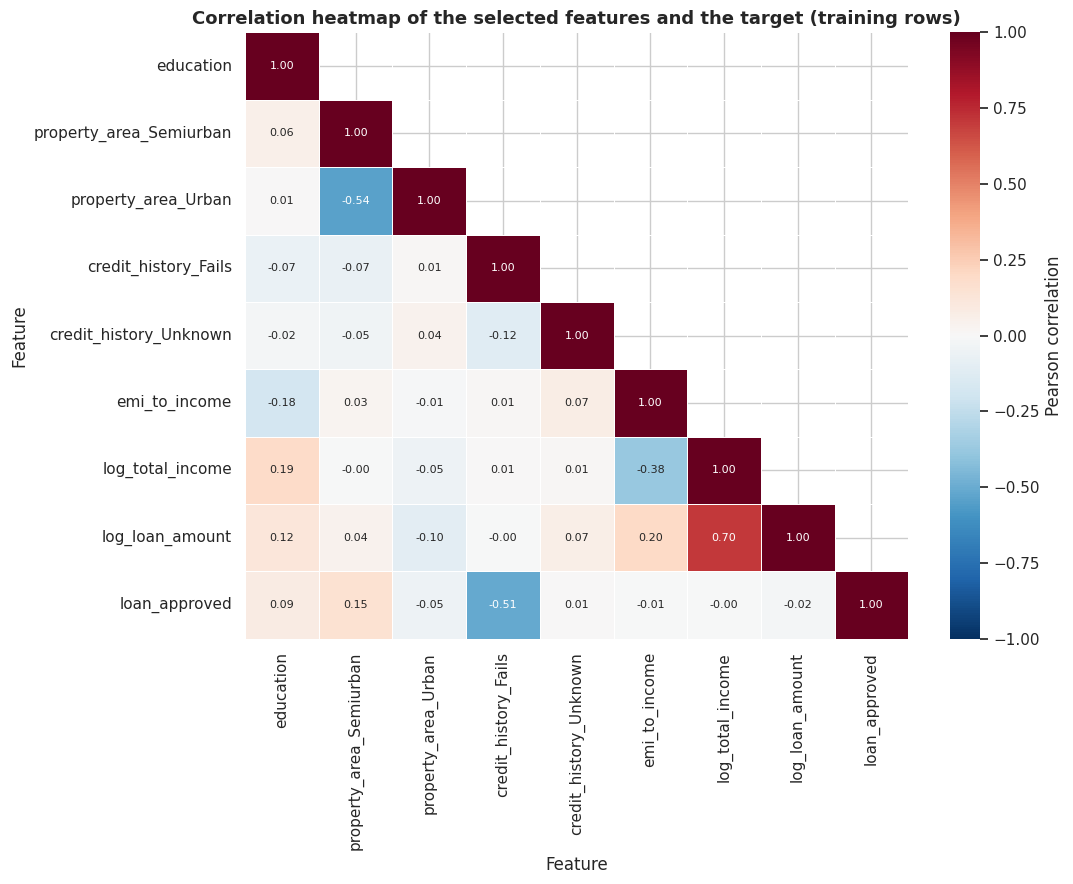

Largest correlation between two selected features: 0.70 (the limit was 0.8)


In [28]:
# The final feature set: heatmap and a check that no redundancy remains
final_corr = train_s[FINAL_FEATURES + ["loan_approved"]].corr()
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(final_corr, mask=np.triu(np.ones_like(final_corr, dtype=bool), k=1), annot=True, fmt=".2f", annot_kws={"size": 8}, cmap="RdBu_r",
            center=0, vmin=-1, vmax=1, linewidths=.4, cbar_kws={"label": "Pearson correlation"}, ax=ax)
ax.set_title("Correlation heatmap of the selected features and the target (training rows)", fontsize=13, fontweight="bold")
ax.set_xlabel("Feature"); ax.set_ylabel("Feature")
save_fig("12_correlation_heatmap_selected")

off_diag = final_corr.loc[FINAL_FEATURES, FINAL_FEATURES].abs().where(~np.eye(len(FINAL_FEATURES), dtype=bool))
print(f"Largest correlation between two selected features: {off_diag.max().max():.2f} (the limit was {REDUNDANCY_R})")

The largest correlation among the selected features is **0.70** (`log_total_income` and `log_loan_amount`: larger incomes take larger loans), below the 0.80 limit, so no redundant pair remains. Among all selected features, only `credit_history_Fails` has a strong link with the target (-0.51).

### Does the preprocessing actually help? A quick check
This is **not** the modelling task (that comes later). It is a quick test of whether the prepared data is better than the raw data, using a plain logistic regression and 5-fold cross-validation on the training rows. Three versions are compared:

* **A. Raw:** only the original numeric columns, median-filled, no encoding, no scaling, no new features.
* **B. All features:** every engineered and encoded candidate, scaled, without selection.
* **C. Selected:** the final feature set.
* **D. Evidence only:** just the features with a statistically supported link to approval (no domain-essential extras).

,accuracy,accuracy_sd,roc_auc,roc_auc_sd,f1
version,,,,,
A. Raw numeric columns,0.796,0.025,0.643,0.045,0.869
B. All engineered features,0.786,0.020,0.728,0.023,0.860
C. Selected (8 features),0.798,0.027,0.732,0.023,0.870
D. Evidence only (3 features),0.798,0.027,0.742,0.038,0.870


Reference: always predicting 'approved' gives 68.6% accuracy and a ROC-AUC of 0.50.


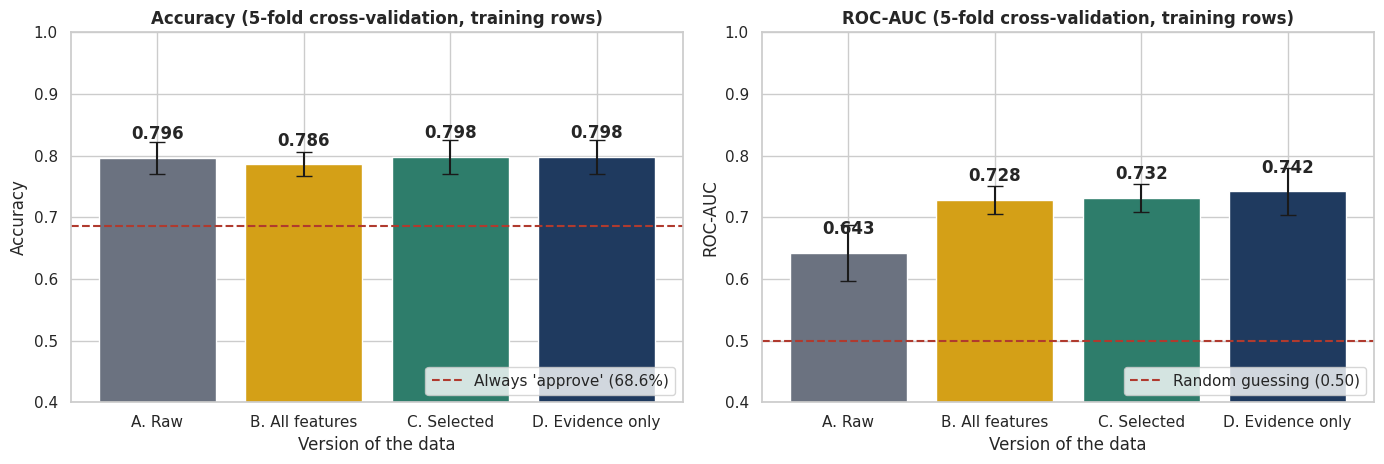

In [29]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
y = y_tr.values
Xa = train_raw[["applicant_income", "coapplicant_income", "loan_amount_k", "loan_term_months"]].assign(credit_history=train_raw["credit_history"].map({"Meets": 1, "Fails": 0}))
versions = {
    "A. Raw numeric columns":     (Xa,                           make_pipeline(SimpleImputer(strategy="median"), LogisticRegression(max_iter=5000))),
    "B. All engineered features": (train_s[CANDIDATES],          make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000))),
    f"C. Selected ({len(FINAL_FEATURES)} features)": (train_s[FINAL_FEATURES], LogisticRegression(max_iter=5000)),
    f"D. Evidence only ({len(EVIDENCE_ONLY)} features)": (train_s[EVIDENCE_ONLY], LogisticRegression(max_iter=5000)),
}
rows = []
for name, (X, model) in versions.items():
    res = cross_validate(model, X, y, cv=cv, scoring=["accuracy", "roc_auc", "f1"])
    rows.append({"version": name, "accuracy": res["test_accuracy"].mean(), "accuracy_sd": res["test_accuracy"].std(),
                 "roc_auc": res["test_roc_auc"].mean(), "roc_auc_sd": res["test_roc_auc"].std(), "f1": res["test_f1"].mean()})
cv_table = pd.DataFrame(rows).set_index("version")
display(cv_table)
print(f"Reference: always predicting 'approved' gives {y.mean():.1%} accuracy and a ROC-AUC of 0.50.")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
bar_colors, labels = [GREY, GOLD, GREEN, BLUE], ["A. Raw", "B. All features", "C. Selected", "D. Evidence only"]
for ax, metric, title in [(axes[0], "accuracy", "Accuracy"), (axes[1], "roc_auc", "ROC-AUC")]:
    ax.bar(range(4), cv_table[metric], yerr=cv_table[f"{metric}_sd"], color=bar_colors, capsize=6)
    for i, v in enumerate(cv_table[metric]): ax.text(i, v + 0.03, f"{v:.3f}", ha="center", fontweight="bold")
    ax.set_xticks(range(4)); ax.set_xticklabels(labels); ax.set_ylim(0.4, 1.0)
    ax.set_title(f"{title} (5-fold cross-validation, training rows)", fontweight="bold"); ax.set_xlabel("Version of the data"); ax.set_ylabel(title)
    if metric == "accuracy": ax.axhline(y.mean(), ls="--", color=RED, label=f"Always 'approve' ({y.mean():.1%})")
    else: ax.axhline(0.5, ls="--", color=RED, label="Random guessing (0.50)")
    ax.legend(loc="lower right")
save_fig("13_preprocessing_impact")

**Result.** The ROC-AUC (how well applicants are ranked from likely-approve to likely-reject) improves from **0.643** on the raw columns to **0.728** with all engineered features, **0.732** with the selected set and **0.742** with the evidence-only set. Accuracy stays near **0.80** for every version that contains credit history, because that single feature already carries most of it.

**How to read this honestly:**
* Preparing the data lifts the ranking quality by about 0.09 AUC. The error bars (about 0.02 to 0.04) are small compared with that jump.
* The gap between versions C and D is **inside the noise**, so adding the four domain-essential features costs nothing measurable. Version C is kept because lenders need affordability information.
* Version B (all 24 features) does slightly worse than the selected sets on accuracy, which supports removing redundant and noisy columns.
* Accuracy alone would have hidden all of this, since an "always approve" rule already scores 68.6%.

## Part 5: Final Machine-Learning Dataset
The final dataset keeps the selected features (encoded, capped and scaled), the target `loan_approved`, and a `split` column that says whether each row belongs to the training or hold-out part. Two further files are written: the readable **cleaned dataset** (after missing-value handling and feature engineering, before encoding and scaling) and the preprocessing parameters.

In [30]:
ml_ready = scaled_all[FINAL_FEATURES + ["loan_approved", "split"]].copy()

# Cleaned dataset: readable, filled, with engineered features, before capping / encoding / scaling
cleaned_out = cleaned_all[[c for c in cleaned_all.columns if c not in ("loan_status", "split")] + ["loan_status", "split"]].copy()

# --- Validation checks
checks = {
    "No missing values":                        bool(ml_ready.isna().sum().sum() == 0),
    "Every column is numeric":                  bool(all(pd.api.types.is_numeric_dtype(t) for t in ml_ready.drop(columns="split").dtypes)),
    "No infinite values":                       bool(np.isfinite(ml_ready.drop(columns="split")).all().all()),
    "No duplicate rows":                        bool(ml_ready.duplicated().sum() == 0),
    "Target encoded as 0/1":                    bool(set(ml_ready["loan_approved"].unique()) == {0, 1}),
    "No pair of features with |r| >= 0.80":     bool(off_diag.max().max() < REDUNDANCY_R),
    "Same row count as the cleaned dataset":    bool(len(ml_ready) == len(cleaned_out) == len(df_all)),
    "Scaler fitted on training rows only":      bool(np.allclose(scaled_all.loc[scaled_all["split"] == "train", CONT_FEATURES].mean(), 0, atol=1e-9)
                                                     and not np.allclose(scaled_all.loc[scaled_all["split"] == "holdout", CONT_FEATURES].mean(), 0, atol=1e-9)),
}
readiness = pd.DataFrame({"check": list(checks), "passed": ["Yes" if v else "NO" for v in checks.values()]})
display(readiness)
assert all(checks.values()), "A readiness check failed"

print(f"\nFinal ML-ready dataset: {ml_ready.shape[0]} rows x {ml_ready.shape[1]} columns "
      f"({len(FINAL_FEATURES)} features + target + split)")
print(ml_ready.groupby("split")["loan_approved"].agg(rows="count", approval_rate="mean").round(3).to_string())
display(ml_ready.head(8))
display(ml_ready[FINAL_FEATURES].describe().T)

,check,passed
0,No missing values,Yes
1,Every column is numeric,Yes
2,No infinite values,Yes
3,No duplicate rows,Yes
4,Target encoded as 0/1,Yes
5,No pair of features with |r| >= 0.80,Yes
6,Same row count as the cleaned dataset,Yes
7,Scaler fitted on training rows only,Yes



Final ML-ready dataset: 614 rows x 10 columns (8 features + target + split)
         rows  approval_rate
split                       
holdout   123          0.691
train     491          0.686


,education,property_area_Semiurban,property_area_Urban,credit_history_Fails,credit_history_Unknown,emi_to_income,log_total_income,log_loan_amount,loan_approved,split
0,1,0,1,0,0,-0.376,0.028,-0.024,1,train
1,1,0,0,0,0,-0.484,0.111,-0.024,0,train
2,1,0,1,0,0,-0.361,-1.341,-1.536,1,holdout
3,0,0,1,0,0,-0.077,-0.318,-0.172,1,train
4,1,0,1,0,0,-0.175,0.080,0.197,1,train
5,1,0,1,0,0,0.358,1.047,1.662,1,train
6,0,0,1,0,0,-0.027,-0.830,-0.706,1,train
7,1,1,0,1,0,0.451,-0.084,0.458,0,holdout


,count,mean,std,min,25%,50%,75%,max
education,614.000,0.782,0.413,0.000,1.000,1.000,1.000,1.000
property_area_Semiurban,614.000,0.379,0.486,0.000,0.000,0.000,1.000,1.000
property_area_Urban,614.000,0.329,0.470,0.000,0.000,0.000,1.000,1.000
credit_history_Fails,614.000,0.145,0.352,0.000,0.000,0.000,0.000,1.000
credit_history_Unknown,614.000,0.081,0.274,0.000,0.000,0.000,0.000,1.000
emi_to_income,614.000,0.019,1.031,-2.343,-0.622,-0.009,0.562,2.269
log_total_income,614.000,-0.015,1.012,-2.484,-0.668,-0.130,0.544,2.373
log_loan_amount,614.000,-0.008,0.997,-2.280,-0.583,-0.024,0.554,2.260


All eight readiness checks pass. The final dataset has **614 rows and 10 columns**: 8 features, the target `loan_approved` and the `split` flag. The continuous features are centred near zero and the 0/1 columns are untouched.

In [31]:
# Save the datasets and the preprocessing parameters
cleaned_out.to_csv(PROC_DIR / "loan_cleaned.csv", index=False)
ml_ready.to_csv(PROC_DIR / "loan_ml_ready.csv", index=False)
ml_ready[ml_ready["split"] == "train"].drop(columns="split").to_csv(PROC_DIR / "loan_ml_ready_train.csv", index=False)
ml_ready[ml_ready["split"] == "holdout"].drop(columns="split").to_csv(PROC_DIR / "loan_ml_ready_holdout.csv", index=False)

params_out = {
    "random_state": RANDOM_STATE, "split": {"train_rows": int((df_all["split"] == "train").sum()), "holdout_rows": int((df_all["split"] == "holdout").sum())},
    "imputation_values": imputation_params,
    "outlier_caps_iqr_1.5": caps,
    "scaler": {"type": "StandardScaler", "features": CONT_FEATURES, "mean": scaler.mean_.tolist(), "scale": scaler.scale_.tolist()},
    "encoding": {"binary": BINARY_MAPS, "one_hot_reference": {"property_area": "Rural", "credit_history": "Meets"}, "target": {"N": 0, "Y": 1}},
    "final_features": FINAL_FEATURES,
}
with open(PROC_DIR / "preprocessing_parameters.json", "w") as f:
    json.dump(params_out, f, indent=2)
print("Saved: loan_cleaned.csv, loan_ml_ready.csv, loan_ml_ready_train.csv, loan_ml_ready_holdout.csv, preprocessing_parameters.json, feature_selection_summary.csv")

Saved: loan_cleaned.csv, loan_ml_ready.csv, loan_ml_ready_train.csv, loan_ml_ready_holdout.csv, preprocessing_parameters.json, feature_selection_summary.csv


In [32]:
# Data dictionary for the final dataset: what every column is and how it was built
DICTIONARY = {
    "married": ("Applicant is married (1 = yes)", "Binary label encoding"),
    "dependents": ("Number of dependents (0 to 3, where 3 means 3 or more)", "'3+' converted to 3, missing filled with 0, StandardScaler"),
    "education": ("Applicant is a graduate (1 = graduate)", "Binary label encoding"),
    "self_employed": ("Applicant is self-employed (1 = yes)", "Missing filled with 'No', binary label encoding"),
    "loan_term_months": ("Loan term in months", "Missing filled with 360, StandardScaler"),
    "property_area_Semiurban": ("Property is in a semi-urban area (reference: Rural)", "One-hot encoding"),
    "property_area_Urban": ("Property is in an urban area (reference: Rural)", "One-hot encoding"),
    "credit_history_Fails": ("Credit history does not meet guidelines (reference: Meets)", "One-hot encoding"),
    "credit_history_Unknown": ("Credit history is missing (reference: Meets)", "Missing values kept as their own category, one-hot encoding"),
    "has_coapplicant": ("Co-applicant has income (1 = yes)", "Engineered: coapplicant_income > 0"),
    "emi_to_income": ("Monthly instalment as a share of total income", "Engineered: (loan_amount x 1000 / term) / total income, capped, StandardScaler"),
    "household_size": ("People supported by the income", "Engineered: 1 + married + dependents, StandardScaler"),
    "log_applicant_income": ("Applicant income, log scale", "log(1 + income), capped at IQR limits, StandardScaler"),
    "log_coapplicant_income": ("Co-applicant income, log scale", "log(1 + income), capped at IQR limits, StandardScaler"),
    "log_total_income": ("Total income, log scale", "log(1 + total income), capped, StandardScaler"),
    "log_loan_amount": ("Loan amount (thousands), log scale", "Missing filled with the median, log(1 + amount), capped, StandardScaler"),
    "log_income_per_person": ("Income per household member, log scale", "Engineered, log(1 + value), capped, StandardScaler"),
    "gender": ("Applicant is male (1 = male)", "Binary label encoding (removed from the final set for fairness)"),
    "loan_approved": ("TARGET: loan approved (1) or rejected (0)", "Label encoding of Loan_Status"),
    "split": ("Which part of the data the row belongs to", "'train' (80%) or 'holdout' (20%), stratified on the target"),
}
data_dict = pd.DataFrame([(c, *DICTIONARY.get(c, ("", ""))) for c in FINAL_FEATURES + ["loan_approved", "split"]], columns=["column", "description", "how_it_was_built"])
data_dict.to_csv(PROC_DIR / "ml_ready_data_dictionary.csv", index=False)
display(data_dict)

,column,description,how_it_was_built
0,education,Applicant is a graduate (1 = graduate),Binary label encoding
1,property_area_Semiurban,Property is in a semi-urban area (reference: R...,One-hot encoding
2,property_area_Urban,Property is in an urban area (reference: Rural),One-hot encoding
3,credit_history_Fails,Credit history does not meet guidelines (refer...,One-hot encoding
4,credit_history_Unknown,Credit history is missing (reference: Meets),"Missing values kept as their own category, one..."
5,emi_to_income,Monthly instalment as a share of total income,Engineered: (loan_amount x 1000 / term) / tota...
6,log_total_income,"Total income, log scale","log(1 + total income), capped, StandardScaler"
7,log_loan_amount,"Loan amount (thousands), log scale","Missing filled with the median, log(1 + amount..."
8,loan_approved,TARGET: loan approved (1) or rejected (0),Label encoding of Loan_Status
9,split,Which part of the data the row belongs to,"'train' (80%) or 'holdout' (20%), stratified o..."


### Hold-out check
The hold-out rows were set aside at the start and never used to learn anything. A plain logistic regression trained on the training rows is scored on them **once**, only to confirm the dataset behaves sensibly. This is a readiness test, not tuned model performance.

,hold-out
accuracy,0.854
precision,0.832
recall,0.988
f1,0.903
roc_auc,0.854
always-approve accuracy,0.691


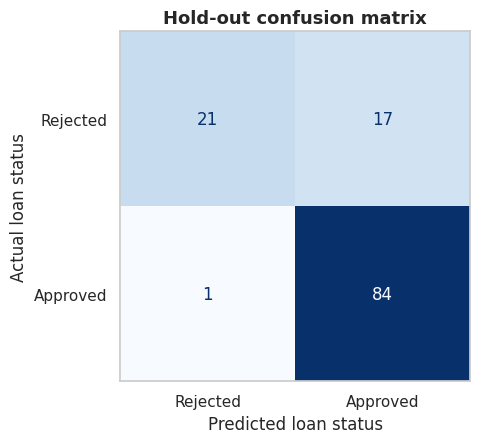

In [33]:
train_part = ml_ready[ml_ready["split"] == "train"]; hold_part = ml_ready[ml_ready["split"] == "holdout"]
final_model = LogisticRegression(max_iter=5000).fit(train_part[FINAL_FEATURES], train_part["loan_approved"])
pred = final_model.predict(hold_part[FINAL_FEATURES]); proba = final_model.predict_proba(hold_part[FINAL_FEATURES])[:, 1]
yh = hold_part["loan_approved"]
holdout_scores = pd.Series({"accuracy": accuracy_score(yh, pred), "precision": precision_score(yh, pred), "recall": recall_score(yh, pred),
                            "f1": f1_score(yh, pred), "roc_auc": roc_auc_score(yh, proba), "always-approve accuracy": yh.mean()}, name="hold-out")
display(holdout_scores.to_frame())

fig, ax = plt.subplots(figsize=(5.5, 4.6))
ConfusionMatrixDisplay.from_predictions(yh, pred, display_labels=["Rejected", "Approved"], cmap="Blues", colorbar=False, ax=ax)
ax.set_title("Hold-out confusion matrix", fontsize=13, fontweight="bold"); ax.set_xlabel("Predicted loan status"); ax.set_ylabel("Actual loan status"); ax.grid(False)
save_fig("14_holdout_confusion_matrix")

**Reading the hold-out result.** The model scores **85.4% accuracy** against 69.1% for "always approve", with a ROC-AUC of **0.854**. It correctly approves 84 of the 85 approvable applicants (recall 98.8%) but correctly rejects only 21 of 38 rejectable ones (55%), so **17 applications that should have been rejected were approved**. In lending, wrongly approving a risky applicant is the costly mistake, so the next stage should be judged on how well it catches rejections, not only on accuracy.

**A caution:** the hold-out has only 123 rows, so this result is noisy and looks better than the cross-validated figures (accuracy about 0.80, AUC about 0.73). The cross-validation estimate is the steadier guide. This check was a readiness test, not a tuned model.

### Proving the pipeline works on brand-new data
The Kaggle **test file** (367 applications, no outcome) goes through the *same fitted pipeline*, with no re-fitting. If the pipeline is truly reusable, the output must have exactly the same columns as the training data and no missing values.

In [34]:
test_std = standardise_types(raw_test).reset_index(drop=True)
test_cleaned, test_scaled = run_pipeline(test_std, PARAMS, scaler)
test_ml = test_scaled[["loan_id"] + FINAL_FEATURES]

assert list(test_ml.columns[1:]) == FINAL_FEATURES
assert test_ml.isna().sum().sum() == 0 and np.isfinite(test_ml[FINAL_FEATURES]).all().all()
test_ml.to_csv(PROC_DIR / "loan_kaggle_test_ml_ready.csv", index=False)
print(f"Unlabelled test file processed: {test_ml.shape[0]} rows x {test_ml.shape[1]} columns, 0 missing values.")
print("Columns identical to the training data:", list(test_ml.columns[1:]) == FINAL_FEATURES)
print("Test applications with an unknown credit history:", int(test_scaled["credit_history_Unknown"].sum()))

Unlabelled test file processed: 367 rows x 9 columns, 0 missing values.
Columns identical to the training data: True
Test applications with an unknown credit history: 29


The pipeline handled all 367 unseen applications without re-fitting anything. 29 of them (7.9%) have an unknown credit history, close to the 8.1% in the training data, which suggests the new applications resemble the ones used for preparation.

### Complete preprocessing log
Every decision, in the order it was applied:

| # | Step | Decision | Fitted on |
|---|---|---|---|
| 1 | Types and names | `Dependents` "3+" to 3; credit history 1/0 to Meets/Fails; clear snake_case names | None |
| 2 | Duplicates | None found (checked with and without `Loan_ID`) | None |
| 3 | Split | 80/20 stratified train/hold-out | None |
| 4 | Missing values | Mode (gender, married, self-employed, dependents, term), median (loan amount), "Unknown" category (credit history) | Training rows |
| 5 | Feature engineering | 11 new features: total income, instalment, affordability ratio, household size and log versions | None (arithmetic) |
| 6 | Outliers | Log transform, then IQR capping at 1.5 x IQR; no rows deleted | Training rows |
| 7 | Encoding | Binary 0/1, one-hot (property area, credit history), ordinal (dependents), target N/Y to 0/1 | Fixed category lists |
| 8 | Scaling | `StandardScaler` on continuous features | Training rows |
| 9 | Feature selection | 24 candidates reduced to 8 using redundancy, evidence, noise probes, domain and fairness rules | Training rows |
| 10 | Validation | Eight readiness checks, cross-validation comparison, one hold-out check, pipeline re-run on unseen data | n/a |

## Answers to the Seven Business Questions

**1. Which features are most relevant to the prediction problem?**
**Credit history** by a wide margin: applicants whose history fails guidelines are approved only about 9% of the time against 79% for those who meet them. **Property area** (semi-urban applicants do better) and **education** show weaker but supported links. Income, loan amount and repayment burden show no relationship with approval *on their own* in this sample, but they are kept as the core affordability measures because lending decisions depend on them.

**2. Which variables require encoding?**
Four two-category columns (`gender`, `married`, `education`, `self_employed`) get binary 0/1 labels; the unordered three-category columns `property_area` and `credit_history` get one-hot encoding; `dependents` stays an ordinal number; and the target `loan_status` is label-encoded (N = 0, Y = 1). The reasoning for each is in section 3.7.

**3. Which variables require scaling or normalisation?**
All continuous features: incomes, loan amount, repayment ratio, loan term, household size and dependents. They are log-transformed where skewed, capped, then standardised with `StandardScaler`. The 0/1 columns are not scaled.

**4. Are there redundant or highly correlated features?**
Yes. Five pairs correlate at 0.80 or above (co-applicant income and its 0/1 flag at 0.99, household size and dependents at 0.93, and three raw-versus-log pairs). After selection, the largest correlation left is 0.70.

**5. How should missing values and outliers be handled?**
**Missing values** (22% of rows had at least one) get a treatment matched to each column: mode for categories, median for the skewed loan amount, and a separate "Unknown" category for credit history. **Outliers** are real applicants, so rows are kept: a log transform removes most of the skew and IQR capping limits the rest. All fill values and limits come from the training rows only.

**6. What preprocessing techniques improve dataset quality?**
Type correction, matched missing-value handling, log transformation and capping, correct encoding, scaling, the affordability features and selection. In a quick cross-validated test they lift the ROC-AUC from 0.64 (raw) to about 0.73 to 0.74. Accuracy stays near 0.80 because credit history already drives it, so the gain is in how well applicants are ranked.

**7. Is the dataset ready for machine learning?**
**Yes, for a first modelling stage, with known limits.** It has no missing values, is fully numeric, has no redundant pairs, is split without leakage, and its pipeline works on new data. Points to carry forward:
* **Small sample:** 614 rows means high variance (cross-validation spread of 0.02 to 0.04 AUC). Use cross-validation, not one split.
* **Imbalanced target (69% approved):** use stratified splits and judge models on recall for rejections, F1 and ROC-AUC, not accuracy alone. Consider class weights.
* **One dominant feature:** credit history drives most of the signal, so gains from other features will be modest.
* **Fairness:** gender and marital status were excluded. Property area could act as a proxy for location, so it should be reviewed before any real use.
* **Small "Unknown" group:** only 43 training applicants have no credit history, so conclusions about them are uncertain.

**Next step (Week 3):** train and compare baseline models (for example logistic regression and random forest) on `loan_ml_ready.csv`, using the same stratified split.